# What kinds of passes do Premier League players play?
### Clustering 4.5 million open-play passes to describe players, 2013 to 2026

This notebook runs the whole project from the first line of data preparation to the interactive page in `docs/`. Every section does one thing, prints what it found, and says what to take from it.

**The question.** What kinds of passes do Premier League players play, and can a player be described by the mix of passes he plays?

**The plan.**

| Part | What it does |
|---|---|
| 1 | Setup |
| 2 | Data: open-play passes, orientation check, the provider's "Chipped" tag |
| 3 | Risk: an expected-completion model (xP) and how well it works |
| 4 | A rule-based yardstick for pass types |
| 5 | **k-means on 4.5 million passes**: choosing k, the flag weight, PCA, the tagging problem, the nine pass types |
| 6 | From passes to players: pass-type shares, reliability, position, goalkeepers |
| 7 | A similar-player search |
| 8 | Adding value: pass xT |
| 9 | Role drift: how a player's passing changes |
| 10 | **Player k-means** by position, pooled over 13 seasons, and the interactive page |
| 11 | What changed in the league |
| 12 | Limitations |

**How to run it.** The raw event data (WhoScored) is *not* in this repository (licence and size). The cells that need it are marked, and the outputs stored in this notebook come from the author's run with the data. Everything from Part 10 on can be re-run from the small files in `data/`. See the README for details.

## 1. Setup

In [1]:
import os, json, time, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib import patheffects as pe
from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier as HGB
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, brier_score_loss, silhouette_score, adjusted_rand_score as ari

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
BG, INK, MUTE, GARNET = '#f7f1e3', '#1d1b18', '#8a8170', '#8b1e2d'
plt.rcParams.update({'font.family': ['Georgia', 'DejaVu Serif'], 'figure.facecolor': BG, 'axes.facecolor': BG, 'savefig.facecolor': BG, 'figure.dpi': 110})

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW = Path(os.environ.get('EPL_RAW', r"D:/CT's Portfolio/data/whoscored/ENG-Premier League"))                       # WhoScored match files (not in the repo)
SPADL = Path(os.environ.get('EPL_SPADL', r"D:/CT's Portfolio/Practice/Possession Value/out/vaep"))                  # SPADL actions (not in the repo)
CACHE, DATA, DOCS = ROOT / 'cache', ROOT / 'data', ROOT / 'docs'
for d in (CACHE, DATA, DOCS): d.mkdir(exist_ok=True)
TAGS = [f'h{a:02d}{a + 1:02d}' for a in range(13, 25)] + ['pl']
SEASONS = [f'{a}-{str(a + 1)[2:]}' for a in range(2013, 2027)]
HAVE_RAW = RAW.exists() and SPADL.exists()
print('repo root:', ROOT); print('raw data available:', HAVE_RAW); print('seasons:', SEASONS[0], 'to', SEASONS[-1], f'({len(SEASONS)} labels; 2026-27 is partial)')

repo root: D:\CT's Portfolio\EPL-Player-Clustering
raw data available: True
seasons: 2013-14 to 2026-27 (14 labels; 2026-27 is partial)


## 2. Data

**Source.** WhoScored event data (every on-the-ball action of every Premier League match), converted to a standard format (SPADL) with start and end coordinates on a 105 x 68 m pitch. **Needs the raw data.**

First look at one season, to see what an action looks like.

In [2]:
def load_actions(tag):
    a = pd.read_parquet(SPADL / f'actions_{tag}.parquet'); g = pd.read_parquet(SPADL / f'games_{tag}.parquet')
    return a, g
a, g = load_actions('h2425')
print(a.shape, '| matches:', a.game_id.nunique())
display(a[['game_id', 'period_id', 'team_id', 'type_name', 'result_name', 'bodypart_name', 'start_x', 'start_y', 'end_x', 'end_y']].head(6))
print(a.type_name.value_counts().head(8).to_string())

(606304, 20) | matches: 380


,game_id,period_id,team_id,type_name,result_name,bodypart_name,start_x,start_y,end_x,end_y
0,1821049,1,170,pass,success,foot,52.605,34.068,63.840,36.244
1,1821049,1,170,pass,success,foot,63.840,36.244,79.590,43.044
2,1821049,1,170,dribble,success,foot,79.590,43.044,72.975,53.992
3,1821049,1,170,pass,success,foot,72.975,53.992,36.015,60.792
4,1821049,1,170,bad_touch,fail,foot,36.645,58.072,36.645,58.072
5,1821049,1,32,take_on,success,foot,38.850,59.772,38.850,59.772


type_name
pass            329536
dribble         139349
clearance        18157
take_on          14577
tackle           13372
throw_in         12502
interception     11496
bad_touch        10478


**Orientation.** Coordinates are absolute, so the away team attacks the other way. I flip the away team (`x -> 105 - x`, `y -> 68 - y`) so every team attacks left to right, and then *check* it instead of trusting it: after flipping, crosses should start near the opposition goal line (x about 91) in both halves, for home and away, and almost never in a team's own half.

In [3]:
def orient(a, g):
    a = a.merge(g[['game_id', 'home_team_id', 'away_team_id']], on='game_id')
    away = (a.team_id == a.away_team_id).to_numpy()
    for c, m in [('start_x', 105), ('end_x', 105), ('start_y', 68), ('end_y', 68)]:
        a.loc[away, c] = m - a.loc[away, c]
    return a, away

a1, away = orient(a, g)
cr = a1[a1.type_name == 'cross'].copy(); cr['side'] = np.where(away[cr.index], 'away', 'home')
print('median start x of crosses, share starting in own half, count:')
display(cr.groupby(['period_id', 'side']).start_x.agg(median='median', own_half=lambda s: (s < 52.5).mean(), n='size'))

median start x of crosses, share starting in own half, count:


median  own_half     n
period_id side                        
1         away  91.140     0.000  1955
          home  90.825     0.000  2441
2         away  91.035     0.000  2242
          home  91.140     0.000  2642

**Open play only.** I keep `pass` and `cross` events. Throw-ins, goal kicks, corners and free kicks are separate event types (already labelled by the provider), so leaving them out stops the clustering from just rediscovering those labels.

**The provider's own pass tags.** The standard format discards the provider's qualifiers, including whether a pass was lofted. I go back to every season's raw match file and pull six tags per pass (Chipped, Longball, HeadPass, Throughball, KeyPass, Cross), then join them on game and event id. **Needs the raw data.** (First run takes a couple of minutes; the result is cached.)

In [4]:
FLAGS = ['Chipped', 'Longball', 'HeadPass', 'Throughball', 'KeyPass', 'Cross']

def scan_flags(season):
    rows = []
    for d in sorted((RAW / season).glob('*__*')):
        f = d / 'raw.json'
        if not f.exists(): continue
        gid = int(d.name.split('__')[1])
        for e in json.loads(f.read_text(encoding='utf-8'))['events']:
            if e['type']['displayName'] != 'Pass': continue
            qs = {q['type']['displayName'] for q in e.get('qualifiers', [])}
            rows.append((gid, e['id'], *[k in qs for k in FLAGS]))
    return pd.DataFrame(rows, columns=['game_id', 'original_event_id', *[k.lower() for k in FLAGS]]).assign(season=season)

fp = CACHE / 'flags_all.parquet'
if fp.exists():
    flags = pd.read_parquet(fp)
else:
    t0 = time.time(); flags = pd.concat([scan_flags(s) for s in SEASONS], ignore_index=True); flags.to_parquet(fp); print(f'scanned in {time.time() - t0:.0f}s')
print(f'{len(flags):,} passes with tags')
display(flags.groupby('season')[['chipped', 'longball', 'headpass', 'throughball', 'keypass']].mean().mul(100).round(1).rename(columns=lambda c: c + ' %'))

4,963,082 passes with tags


,chipped %,longball %,headpass %,throughball %,keypass %
season,,,,,
2013-14,9.800,15.700,7.300,0.300,2.000
2014-15,10.100,16.500,7.800,0.300,1.900
2015-16,9.800,16.500,8.000,0.300,2.000
2016-17,10.000,16.600,7.700,0.300,1.900
2017-18,9.700,15.700,7.900,0.300,1.800
2018-19,10.000,14.600,7.200,0.300,1.800
2019-20,10.500,14.100,7.100,0.200,1.700
2020-21,10.500,13.000,6.600,0.100,1.700
2021-22,10.900,13.400,6.700,0.300,1.800


Only **Chipped** and **Cross** are used later: Throughball is too rare (about 0.3% of passes) and Longball changes its frequency across eras.

**The all-season pass table.** One row per open-play pass, oriented, with the tags joined (about 99.6% of passes match; the rest are dropped), and the geometry I need: displacement `dx`, `dy`, length `L`, the `gain` toward goal, the start's distance from the centre line `start_w`, and `dyf` (sideways movement with the start side flipped, so left and right wings are treated alike).

In [5]:
def build_passes():
    parts = []
    for t in TAGS:
        a, g = load_actions(t); a, _ = orient(a, g)
        p = a[a.type_name.isin(['pass', 'cross'])].dropna(subset=['original_event_id']).copy()
        p['original_event_id'] = p.original_event_id.astype('int64')
        p = p.merge(flags[['game_id', 'original_event_id', 'chipped']], on=['game_id', 'original_event_id'], how='inner')
        parts.append(p[['game_id', 'season', 'date', 'team_id', 'player_id', 'type_name', 'result_name', 'bodypart_name', 'start_x', 'start_y', 'end_x', 'end_y', 'chipped']])
        print(t, f'{len(parts[-1]):,}', end=' | ')
    p = pd.concat(parts, ignore_index=True)
    p['dx'] = p.end_x - p.start_x; p['dy'] = p.end_y - p.start_y; p['L'] = np.hypot(p.dx, p.dy)
    p['gain'] = np.hypot(105 - p.start_x, 34 - p.start_y) - np.hypot(105 - p.end_x, 34 - p.end_y)
    p['ok'] = (p.result_name == 'success').astype('int8'); p['head'] = (p.bodypart_name == 'head').astype('int8')
    p['ch'] = p.chipped.astype('int8'); p['cr'] = (p.type_name == 'cross').astype('int8')
    p['start_w'] = (p.start_y - 34).abs(); p['dyf'] = p.dy * np.where(p.start_y <= 34, 1.0, -1.0)
    return p.drop(columns=['chipped', 'result_name', 'bodypart_name'])

fp = CACHE / 'passes_base.parquet'
if fp.exists(): p = pd.read_parquet(fp)
else: p = build_passes(); p.to_parquet(fp)
print(f'\n{len(p):,} open-play passes, {p.season.nunique()} season labels')
display(p.groupby('season').size().rename('passes').to_frame().T)
display(p.head(4))


4,508,312 open-play passes, 14 season labels


season,2013-14,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25,2025-26,2026-27
passes,339534,333913,331283,333446,342854,346174,346088,357814,340954,342590,355156,337635,330467,70404


,game_id,season,date,team_id,player_id,type_name,start_x,start_y,end_x,end_y,dx,dy,L,gain,ok,head,ch,cr,start_w,dyf
0,719846,2013-14,2013-08-17,24,"68,312.000",pass,51.555,34.680,55.125,30.464,3.570,-4.216,5.524,3.449,1,0,0,0,0.680,4.216
1,719846,2013-14,2013-08-17,24,"14,036.000",pass,54.810,30.260,38.535,41.208,-16.275,10.948,19.615,-16.526,1,0,0,0,3.740,10.948
2,719846,2013-14,2013-08-17,24,"79,050.000",pass,38.535,41.208,26.145,26.588,-12.390,-14.620,19.164,-12.348,1,0,0,0,7.208,14.620
3,719846,2013-14,2013-08-17,24,"14,107.000",pass,26.250,25.772,101.850,15.572,75.600,-10.200,76.285,60.483,0,0,0,0,8.228,-10.200


**What does "Chipped" mean?** I could not find the provider's definition, so I characterise it from the data (2024/25 only). It behaves like a lofted pass: long, forward, completes far less often, never a header.

In [6]:
p24 = p[p.season == '2024-25'].copy()
prof = p24.groupby('ch').agg(passes=('ok', 'size'), median_length_m=('L', 'median'), median_forward_gain_m=('dx', 'median'), completion=('ok', 'mean'))
prof.index = ['not chipped', 'chipped']; display(prof)
print(f"chipped share of open-play passes in 2024-25: {p24.ch.mean():.1%}")

,passes,median_length_m,median_forward_gain_m,completion
not chipped,310628,14.159,2.625,0.863
chipped,27007,33.029,19.215,0.460


chipped share of open-play passes in 2024-25: 8.0%


## 3. Risk: how hard is a pass? (xP)

I want "risk" to be a number, not a word. **xP** is the predicted probability that a pass completes, from a gradient-boosted classifier that sees only what is known when the ball is struck: start and end position, length, direction, header, lofted, cross. It never sees the result. **Risk = 1 - xP.**

**Validation (2024/25).** Folds are split *by match*, so a pass is never scored by a model that trained on its own match. Compared with always predicting the average.

In [7]:
base = ['start_x', 'start_y', 'end_x', 'end_y', 'L', 'dx', 'dy', 'head']
y = p24.ok.to_numpy(); grp_ = p24.game_id.to_numpy()
def cv_pred(feats):
    return cross_val_predict(HGB(max_iter=200, random_state=0), p24[feats], y, cv=GroupKFold(5), groups=grp_, method='predict_proba')[:, 1]
res = {'always the average': np.full(len(y), y.mean()), 'geometry only': cv_pred(base), '+ chipped': cv_pred(base + ['ch']), '+ chipped + cross': cv_pred(base + ['ch', 'cr'])}
display(pd.DataFrame({k: dict(AUC=roc_auc_score(y, v), Brier=brier_score_loss(y, v)) for k, v in res.items()}).T)
pr = res['+ chipped + cross']; d = pd.DataFrame({'xP': pr, 'ok': y}); d['bin'] = pd.cut(d.xP, [0, .2, .4, .6, .75, .9, .95, 1])
print('calibration: predicted vs actual completion in each xP bin')
display(d.groupby('bin', observed=True).agg(n=('ok', 'size'), predicted=('xP', 'mean'), actual=('ok', 'mean')))
cr_ = p24.cr.to_numpy() == 1; print(f'crosses: predicted {pr[cr_].mean():.3f}, actual {y[cr_].mean():.3f}')

,AUC,Brier
always the average,0.500,0.140
geometry only,0.916,0.077
+ chipped,0.919,0.076
+ chipped + cross,0.920,0.075


calibration: predicted vs actual completion in each xP bin


,n,predicted,actual
bin,,,
"(0.0, 0.2]",15053,0.110,0.100
"(0.2, 0.4]",22280,0.297,0.298
"(0.4, 0.6]",21147,0.501,0.503
"(0.6, 0.75]",16616,0.680,0.678
"(0.75, 0.9]",38854,0.839,0.838
"(0.9, 0.95]",37084,0.929,0.927
"(0.95, 1.0]",186601,0.983,0.984


crosses: predicted 0.212, actual 0.216


**Reading it.** AUC about 0.92 means a random completed pass gets a higher xP than a random failed one 92% of the time. The calibration table shows a stated 50% really is about 50%. The cross flag fixes a bias: without it the model predicted 26% completion for crosses against 21.6% actual.

**What xP cannot do.** It has no defenders or pressure, so it measures how hard a *type* of pass is, not how hard it was in that moment, and it says nothing about player skill.

**xP for every season.** Two folds by game parity (train on even games and predict odd, and the reverse), seed fixed so a rebuild gives identical values.

In [8]:
FEATS = base + ['ch', 'cr']
fp = CACHE / 'passes_all.parquet'
if fp.exists():
    p = pd.read_parquet(fp)
else:
    even = (p.game_id % 2 == 0).to_numpy(); p['xP'] = np.nan
    for tr in (even, ~even):
        m = HGB(max_iter=200, random_state=0).fit(p.loc[tr, FEATS], p.ok[tr]); p.loc[~tr, 'xP'] = m.predict_proba(p.loc[~tr, FEATS])[:, 1]
    p.to_parquet(fp)
print(f"pooled out-of-fold AUC {roc_auc_score(p.ok, p.xP):.4f}, Brier {brier_score_loss(p.ok, p.xP):.4f}")
display(p.groupby('season').apply(lambda d: pd.Series(dict(AUC=roc_auc_score(d.ok, d.xP), Brier=brier_score_loss(d.ok, d.xP), mean_xP=d.xP.mean(), actual=d.ok.mean()))).T)

pooled out-of-fold AUC 0.9144, Brier 0.0853


season,2013-14,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25,2025-26,2026-27
AUC,0.908,0.906,0.903,0.907,0.910,0.912,0.918,0.919,0.918,0.918,0.919,0.922,0.922,0.923
Brier,0.090,0.094,0.097,0.093,0.091,0.088,0.085,0.081,0.083,0.082,0.077,0.074,0.077,0.076
mean_xP,0.790,0.782,0.779,0.782,0.786,0.795,0.799,0.810,0.806,0.810,0.820,0.826,0.814,0.815
actual,0.791,0.780,0.776,0.782,0.784,0.794,0.796,0.811,0.804,0.809,0.824,0.831,0.819,0.822


## 4. A rule-based yardstick

Before using any algorithm I wrote down, from football knowledge, the passes I expected to find, with exact numbers (pitch 105 x 68, attacking toward x = 105; `gain` = metres closer to goal). First matching rule wins. These rules are **never used as the clustering**; they are a ruler to hold the clusters against.

In [9]:
inbox = lambda x, y: (x >= 88.5) & (y >= 13.84) & (y <= 54.16)
p['rule'] = np.select(
    [p.cr == 1, inbox(p.end_x, p.end_y) & ~inbox(p.start_x, p.start_y) & (p.dx >= 10), (p.start_x >= 70) & (p.end_x >= 70), (p.dy.abs() >= 30) & (p.L >= 30),
     (p.L >= 32) & (p.dx >= 20), p.gain >= 10, p.dx <= -5, p.dx >= 5],
    ['Cross', 'Box entry', 'Final-third combination', 'Switch', 'Long ball', 'Progressive', 'Back / recycle', 'Short forward'], 'Sideways')
t = p[p.season == '2024-25'].groupby('rule').agg(share=('ok', lambda s: len(s) / (p.season == '2024-25').sum()), completion=('ok', 'mean'), mean_xP=('xP', 'mean'), median_length=('L', 'median')).sort_values('mean_xP', ascending=False)
display(t)

,share,completion,mean_xP,median_length
rule,,,,
Back / recycle,0.204,0.976,0.975,15.812
Sideways,0.221,0.913,0.913,11.412
Short forward,0.169,0.905,0.897,13.298
Final-third combination,0.157,0.830,0.821,10.735
Progressive,0.130,0.745,0.737,18.321
Switch,0.023,0.694,0.706,43.548
Box entry,0.020,0.505,0.486,24.340
Long ball,0.049,0.372,0.359,43.574
Cross,0.027,0.216,0.207,25.633


The risk gradient is what football suggests: back passes are almost safe (xP 0.98), crosses and long balls are the dangerous ones. Cutbacks were too rare to be their own type (0.1% of passes) and the provider's through-ball tag is on only about 0.3% of passes, so I did not separate those.

## 5. k-means on 4.5 million passes

### 5.1 Features and scaling
Each pass is described by six numbers: `start_x`, `start_w`, `dx`, `dyf` (z-scored with pooled mean and SD) and the two yes/no flags `chipped`, `cross` (kept as raw 0/1 and given a weight to test). z-scoring a rare flag would make a chipped pass look 3.7 SD from a grounded one, so the flags are not z-scored.

Not used as inputs: `end_x` (start plus displacement, so it would double-count), length, angle and gain (functions of the others) and **xP**: it is a function of the same inputs, so keeping it out lets me use it afterwards as a check.

In [10]:
NUM = ['start_x', 'start_w', 'dx', 'dyf']
mu, sd = p[NUM].mean(), p[NUM].std()
def X_of(d, w_ch=1.0, w_cr=1.0):
    Z = ((d[NUM] - mu) / sd).to_numpy(np.float32)
    return np.column_stack([Z, w_ch * d.ch.to_numpy(np.float32), w_cr * d.cr.to_numpy(np.float32)])
def strat_sample(d, n_total, seed):
    per = n_total // d.season.nunique()
    return pd.concat([x.sample(min(len(x), per), random_state=seed) for _, x in d.groupby('season')])
display(pd.DataFrame({'mean': mu, 'SD': sd}).T)

,start_x,start_w,dx,dyf
mean,51.236,17.092,5.193,4.161
SD,22.593,9.573,15.445,13.737


### 5.2 How many clusters? Silhouette and stability
For every k from 4 to 20, k-means is fitted on a 300,000-pass sample (equal numbers per season). **Silhouette** (how well each pass fits its cluster; near 0.2 means clusters overlap a lot). **Stability**: fit k-means on two different disjoint 100,000-pass samples and compare their groupings on a common sample with the adjusted Rand index (ARI; 1.0 = identical). Flag weight 1 for now. (Takes a couple of minutes.)

175s


,silhouette,stability_ari,smallest_cluster
k,,,
4,0.227,0.968,0.156
5,0.218,0.955,0.075
6,0.207,0.769,0.067
7,0.215,0.577,0.056
8,0.212,0.798,0.051
9,0.211,0.952,0.047
10,0.213,0.834,0.030
11,0.215,0.620,0.028
12,0.201,0.548,0.028


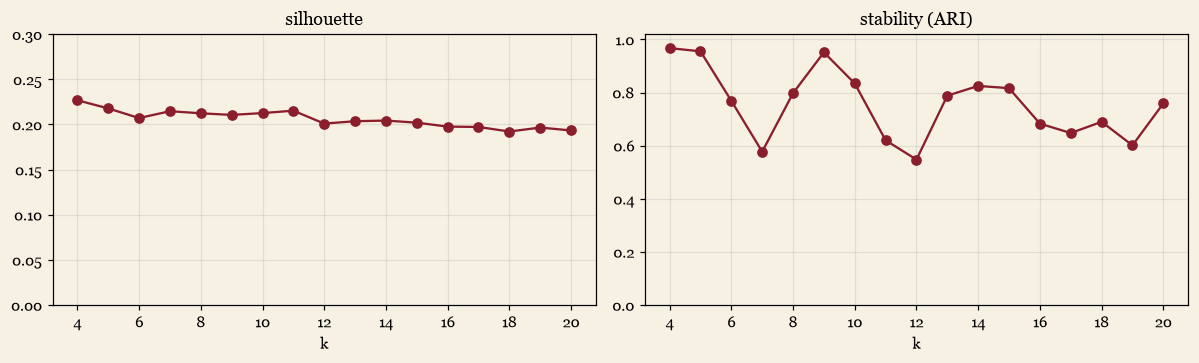

In [11]:
def sweep(ks, w=1.0, n_fit=300_000, n_ev=100_000):
    fit = strat_sample(p, n_fit, 0); Xf = X_of(fit, w, w); ev = strat_sample(p, n_ev, 99); Xe = X_of(ev, w, w)
    sil_idx = np.random.RandomState(1).choice(len(Xf), 20_000, replace=False); rows = []
    for k in ks:
        km = KMeans(k, n_init=3, random_state=0).fit(Xf); sil = silhouette_score(Xf[sil_idx], km.labels_[sil_idx]); aris = []
        for r in range(2):
            lab = [KMeans(k, n_init=2, random_state=r * 2 + s).fit(X_of(strat_sample(p, 100_000, 10 * r + s + 1000), w, w)).predict(Xe) for s in (0, 1)]
            aris.append(ari(lab[0], lab[1]))
        rows.append(dict(k=k, silhouette=sil, stability_ari=np.mean(aris), smallest_cluster=np.bincount(km.labels_).min() / len(Xf)))
    return pd.DataFrame(rows).set_index('k')

t0 = time.time(); sw1 = sweep(range(4, 21), w=1.0); print(f'{time.time() - t0:.0f}s'); display(sw1)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4)); sw1.silhouette.plot(ax=ax[0], marker='o', color=GARNET, title='silhouette'); sw1.stability_ari.plot(ax=ax[1], marker='o', color=GARNET, title='stability (ARI)')
for x in ax: x.set_ylim(0, 1.02 if x is ax[1] else 0.3); x.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Reading it.** Silhouette is about 0.21 for every k from 5 to 13: passes do not form separate islands, they form a smooth continuum, so any set of clusters is a useful *slicing*, not a discovery. Stability jumps around (k = 4, 5 and 9 reproduce; k = 7, 11 and 12 do not).

### 5.3 The weight of the two flags
The flags are a modelling choice, so I test weights 0.5, 1, 2 and 3 around k = 9 to 11.

In [12]:
t0 = time.time(); wt = {w: sweep([9, 10, 11], w=w) for w in (0.5, 1.0, 2.0, 3.0)}; print(f'{time.time() - t0:.0f}s')
display(pd.concat({f'weight {w}': d[['silhouette', 'stability_ari']] for w, d in wt.items()}, axis=1).T)

121s


k                           9     10    11
weight 0.5 silhouette    0.214 0.214 0.198
           stability_ari 0.920 0.842 0.564
weight 1.0 silhouette    0.211 0.213 0.215
           stability_ari 0.952 0.834 0.620
weight 2.0 silhouette    0.217 0.215 0.221
           stability_ari 0.683 0.958 0.762
weight 3.0 silhouette    0.228 0.231 0.229
           stability_ari 0.788 0.795 0.963

**Reading it.** At weight 0.5 and 1 the flags just define one lofted cluster. At weight 2 crosses separate from lofted forward balls, and the stable setting is **k = 10** (ARI about 0.96). At weight 3 the stable setting moves to k = 11. The data do not choose the weight; they only tell me what each choice implies. I chose **weight 2, k = 10**, because the weight-2 and weight-3 solutions agree on the same partition (checked later in Part 5.6).

### 5.4 Is PCA needed?
The source post that inspired this project used PCA. Test: cluster on all six components, then fewer.

In [13]:
fit = strat_sample(p, 300_000, 0); Xf = X_of(fit, 2, 2); ev = strat_sample(p, 100_000, 99); Xe = X_of(ev, 2, 2)
base_lab = KMeans(10, n_init=10, random_state=0).fit(Xf).predict(Xe); pc = PCA().fit(Xf)
print('variance explained by each component:', np.round(pc.explained_variance_ratio_, 3))
rows = []
for nc in (6, 5, 4, 3, 2):
    P = PCA(nc).fit(Xf); lab = KMeans(10, n_init=10, random_state=0).fit(P.transform(Xf)).predict(P.transform(Xe))
    rows.append((nc, P.explained_variance_ratio_.sum(), ari(lab, base_lab)))
display(pd.DataFrame(rows, columns=['components kept', 'variance kept', 'ARI vs no PCA']).set_index('components kept'))

variance explained by each component: [0.349 0.228 0.188 0.162 0.057 0.017]


,variance kept,ARI vs no PCA
components kept,,
6,1.000,1.000
5,0.983,0.947
4,0.926,0.884
3,0.764,0.495
2,0.576,0.262


**Reading it.** PCA only rotates the features: keeping all six reproduces the clustering exactly. Dropping to two or three components destroys it (ARI 0.26 to 0.50), and four or five components still change it, because the smallest components are essentially the two flags (so the lofted information is lost first). There is no collinearity left to remove, so **PCA is not needed for the clustering**. I use it later only to draw two-dimensional maps.

### 5.5 The final fit, and the tagging problem
Fit k-means (weight 2, k = 10) on the 300,000-pass sample, assign **every** pass to its nearest centre, and number the clusters by how far forward they go.

In [14]:
km = KMeans(10, n_init=10, random_state=0).fit(Xf)
p['cl10'] = km.predict(X_of(p, 2, 2))
order = p.groupby('cl10').dx.median().sort_values().index.tolist(); p['cl10'] = p.cl10.map({c: i for i, c in enumerate(order)})
g = p.groupby('cl10')
display(pd.DataFrame(dict(share_pct=g.size() / len(p) * 100, start_x=g.start_x.median(), start_w=g.start_w.median(), dx=g.dx.median(), dyf=g.dyf.median(), length=g.L.median(),
                          chipped=g.ch.mean(), cross=g.cr.mean(), mean_xP=g.xP.mean(), completion=g.ok.mean())))

,share_pct,start_x,start_w,dx,dyf,length,chipped,cross,mean_xP,completion
cl10,,,,,,,,,,
0,10.500,43.680,24.888,-10.290,12.988,18.384,0.014,0.003,0.958,0.958
1,11.776,67.515,9.656,-1.995,6.596,11.222,0.012,0.000,0.832,0.831
2,17.402,72.450,27.540,-0.735,3.808,9.839,0.010,0.004,0.845,0.844
3,11.372,34.545,8.772,2.730,16.252,18.859,0.004,0.000,0.937,0.937
4,2.969,91.560,24.344,3.360,22.848,25.038,0.836,0.946,0.224,0.227
5,12.329,33.075,8.024,7.245,-11.220,15.377,0.020,0.000,0.893,0.894
6,11.864,64.680,13.328,7.980,-10.064,14.471,0.030,0.000,0.863,0.865
7,13.152,36.120,25.432,10.395,0.884,12.502,0.020,0.000,0.713,0.714
8,4.431,46.830,18.564,26.775,22.032,38.553,0.935,0.000,0.482,0.483


Clusters 8 and 9 are both long, forward and mostly lofted. Before trusting that split I checked whether it survives over time, because the **Chipped tag looked unstable**. Test on passes defined by geometry alone (30 m or more long, 15 m or more gained, not a cross): what share carries the Chipped tag, season by season?

In [15]:
lf = p[(p.L >= 30) & (p.dx >= 15) & (p.cr == 0)].copy()
t = pd.DataFrame({'long_forward_passes': lf.groupby('season').size(), 'share_of_all_passes_pct': lf.groupby('season').size() / p.groupby('season').size() * 100, 'chip_share': lf.groupby('season').ch.mean()})
display(t)
m = lf[lf.season == '2023-24'].assign(month=lambda d: pd.to_datetime(d.date).dt.to_period('M')).groupby('month').ch.mean()
print('2023-24 month by month, share of long forward passes tagged Chipped:'); display(m.round(2).to_frame().T)

,long_forward_passes,share_of_all_passes_pct,chip_share
season,,,
2013-14,32912,9.693,0.345
2014-15,32796,9.822,0.336
2015-16,32773,9.893,0.325
2016-17,33779,10.130,0.350
2017-18,32049,9.348,0.374
2018-19,29004,8.378,0.451
2019-20,29344,8.479,0.497
2020-21,28695,8.020,0.543
2021-22,28637,8.399,0.543


2023-24 month by month, share of long forward passes tagged Chipped:


month,2023-08,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05
ch,0.660,0.620,0.590,0.510,0.460,0.470,0.450,0.400,0.440,0.490


**Reading it.** The number of long forward passes moves slowly (about 9.7% of passes in 2013/14 to 7.6% in 2024/25), but the share tagged Chipped swings from about 34% (2013 to 2017) to about 58% (2022/23) and back to 43%, and in 2023/24 it **steps down in the middle of the season** (about 0.6 in August to October, about 0.45 from December). A third of long forward passes do not stop being lofted in the middle of a season. I judge this a tagging change, though I cannot prove it.

**Decision: merge clusters 8 and 9 into one "long forward ball".** The merged cluster follows the geometry and does not depend on the unreliable tag. That leaves **nine pass types**. Crosses stay separate because they come from the event type, not the tag.

In [16]:
p['cl'] = p.cl10.where(p.cl10 < 9, 8).astype('int8')
NAME = ['The Recycle', 'The Link-up', 'The Wing Combo', 'The Diagonal', 'The Cross', 'The Out-Ball', 'The Push Wide', 'The Down-the-Line', 'The Long Ball']
DESC = ['wide back pass, inward', 'short pass through the middle, attacking half', 'short pass on the wing, final third', 'central pass across the pitch, from deep', 'delivery into the box',
        'central ball out to the flank', 'forward ball out wide, attacking half', 'wide pass up the touchline', 'long ball forward, often from deep']
COL = ['#8d99ae', '#1d4e89', '#e09f3e', '#2a9d8f', '#9e2a2b', '#6a994e', '#e76f51', '#8e5572', '#3d405b']
print('cluster share by season (%), so you can see the vocabulary is stable:')
display((pd.crosstab(p.season, p.cl, normalize='index') * 100).round(1).rename(columns=dict(enumerate(NAME))).T)

cluster share by season (%), so you can see the vocabulary is stable:


season,2013-14,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25,2025-26,2026-27
cl,,,,,,,,,,,,,,
The Recycle,9.900,9.800,9.400,9.800,10.200,10.600,11.000,11.000,11.000,10.900,10.700,11.000,11.000,10.900
The Link-up,12.700,12.900,12.400,12.800,12.100,11.300,10.600,11.200,10.700,10.800,12.100,11.600,11.700,12.300
The Wing Combo,17.000,17.100,17.900,17.400,17.800,18.800,18.200,17.400,17.600,16.900,16.700,17.000,16.500,16.400
The Diagonal,10.700,10.500,10.200,10.400,10.900,10.600,11.300,12.000,11.700,12.400,12.300,12.200,12.400,12.200
The Cross,3.500,3.400,3.400,3.300,3.000,2.800,2.900,2.700,2.800,2.700,2.600,2.700,2.900,2.800
The Out-Ball,11.800,11.500,11.400,11.400,11.500,11.500,12.200,12.900,12.900,13.300,13.300,13.300,13.100,13.200
The Push Wide,12.300,12.200,12.400,12.200,12.000,11.900,11.200,11.200,11.200,11.100,11.700,12.300,12.500,12.900
The Down-the-Line,12.900,13.100,13.500,13.000,13.300,13.900,13.900,13.200,13.600,13.300,12.900,12.400,12.200,11.500
The Long Ball,9.300,9.600,9.400,9.700,9.100,8.600,8.600,8.300,8.500,8.500,7.700,7.400,7.800,7.800


### 5.6 Does the result reproduce, and is it stable across eras?
Two checks. (1) Fit on only 2013/14 to 2018/19 and separately on 2019/20 to 2026/27 and compare on the same passes (a *temporal holdout*), against a control of two random samples of the same size. (2) The weight-2 k = 10 solution against the weight-3 k = 11 solution.

In [17]:
def samp(d, n, seed): return pd.concat([x.sample(min(len(x), n // d.season.nunique()), random_state=seed) for _, x in d.groupby('season')])
early, late = p[p.season <= '2018-19'], p[p.season >= '2019-20']
fe, fl = samp(early, 150_000, 1), samp(late, 150_000, 2); fa, fb = samp(p, 150_000, 5), samp(p, 150_000, 6); evs = samp(p, 100_000, 99); Xe2 = X_of(evs, 2, 2)
fit_ = lambda d: KMeans(10, n_init=10, random_state=0).fit(X_of(d, 2, 2))
print('temporal holdout ARI (2013-19 fit vs 2019-26 fit):', round(ari(fit_(fe).predict(Xe2), fit_(fl).predict(Xe2)), 3))
print('control ARI (two random samples):               ', round(ari(fit_(fa).predict(Xe2), fit_(fb).predict(Xe2)), 3))
k11 = KMeans(11, n_init=10, random_state=0).fit(X_of(strat_sample(p, 300_000, 0), 3, 3)).predict(X_of(p, 3, 3))
print('weight 2 k=10 vs weight 3 k=11, all passes ARI:', round(ari(p.cl10, k11), 3))

temporal holdout ARI (2013-19 fit vs 2019-26 fit): 0.834


control ARI (two random samples):                0.967


weight 2 k=10 vs weight 3 k=11, all passes ARI: 0.937


**Reading it.** Clusters fitted on the early era and on the late era agree at ARI about 0.83 (against 0.97 for two random samples), so the structure carries across eras but not identically; part of the gap is real change in play, part is tagging. The two stable settings agree at ARI about 0.94, so the cross-versus-lofted split is not a quirk of one weight.

### 5.7 The nine pass types
Names are my reading of the numbers. Completion is the *actual* rate, which was never an input. (An xP that tracks the clusters would not be independent evidence: xP is built from the same inputs.) Value is pass xT, explained in Part 8; the grid is fitted only on seasons before 2024/25, so here I use 2024/25 onward only (out of sample).

In [18]:
grid = pd.read_csv(DATA / 'xt_grid_pre2024.csv').to_numpy()            # 8 x 12 expected-threat grid, fitted on seasons before 2024-25 (see Part 8)
def cell(x, y, nx=12, ny=8): return np.clip((y / 68 * ny).astype(int), 0, ny - 1) * nx + np.clip((x / 105 * nx).astype(int), 0, nx - 1)
flat = grid.flatten()
p['xt'] = (flat[cell(p.end_x.to_numpy(), p.end_y.to_numpy())] - flat[cell(p.start_x.to_numpy(), p.start_y.to_numpy())]) * p.ok
rec = p[p.season >= '2024-25']; g = p.groupby('cl'); gr = rec.groupby('cl')
nine = pd.DataFrame(dict(name=NAME, what=DESC, share_pct=g.size() / len(p) * 100, completion=g.ok.mean(), mean_xP=g.xP.mean(), median_length_m=g.L.median(), median_forward_m=g.dx.median(),
                         chipped=g.ch.mean(), xT_per_100_passes=gr.xt.mean() * 100, share_of_all_pass_xT_pct=gr.xt.sum() / rec.xt.sum() * 100))
nine.index.name = 'type'; display(nine); nine.to_csv(DATA / 'nine_pass_types.csv')

,name,what,share_pct,completion,mean_xP,median_length_m,median_forward_m,chipped,xT_per_100_passes,share_of_all_pass_xT_pct
type,,,,,,,,,,
0,The Recycle,"wide back pass, inward",10.500,0.958,0.958,18.384,-10.290,0.014,-0.073,-5.639
1,The Link-up,"short pass through the middle, attacking half",11.776,0.831,0.832,11.222,-1.995,0.012,0.151,12.418
2,The Wing Combo,"short pass on the wing, final third",17.402,0.844,0.845,9.839,-0.735,0.010,0.084,9.831
3,The Diagonal,"central pass across the pitch, from deep",11.372,0.937,0.937,18.859,2.730,0.004,0.025,2.175
4,The Cross,delivery into the box,2.969,0.227,0.224,25.038,3.360,0.836,1.891,37.195
5,The Out-Ball,central ball out to the flank,12.329,0.894,0.893,15.377,7.245,0.020,0.026,2.370
6,The Push Wide,"forward ball out wide, attacking half",11.864,0.865,0.863,14.471,7.980,0.030,0.128,11.210
7,The Down-the-Line,wide pass up the touchline,13.152,0.714,0.713,12.502,10.395,0.020,0.118,10.109
8,The Long Ball,"long ball forward, often from deep",8.636,0.406,0.408,43.034,36.120,0.622,0.381,20.331


**Reading it.** Risk and value go together: the valuable passes are the ones that fail most often. Crosses are about 3% of passes but about 37% of all pass threat; long forward balls are about 8% of passes and 20% of threat; the wide back pass is slightly negative. Completion runs from 96% (The Recycle) to 23% (The Cross).

**What the nine passes look like in one season.** Thin arrows are real passes from that season; the black arrow is the typical one (median start and displacement). Every pass is mirrored so it starts in the lower half.

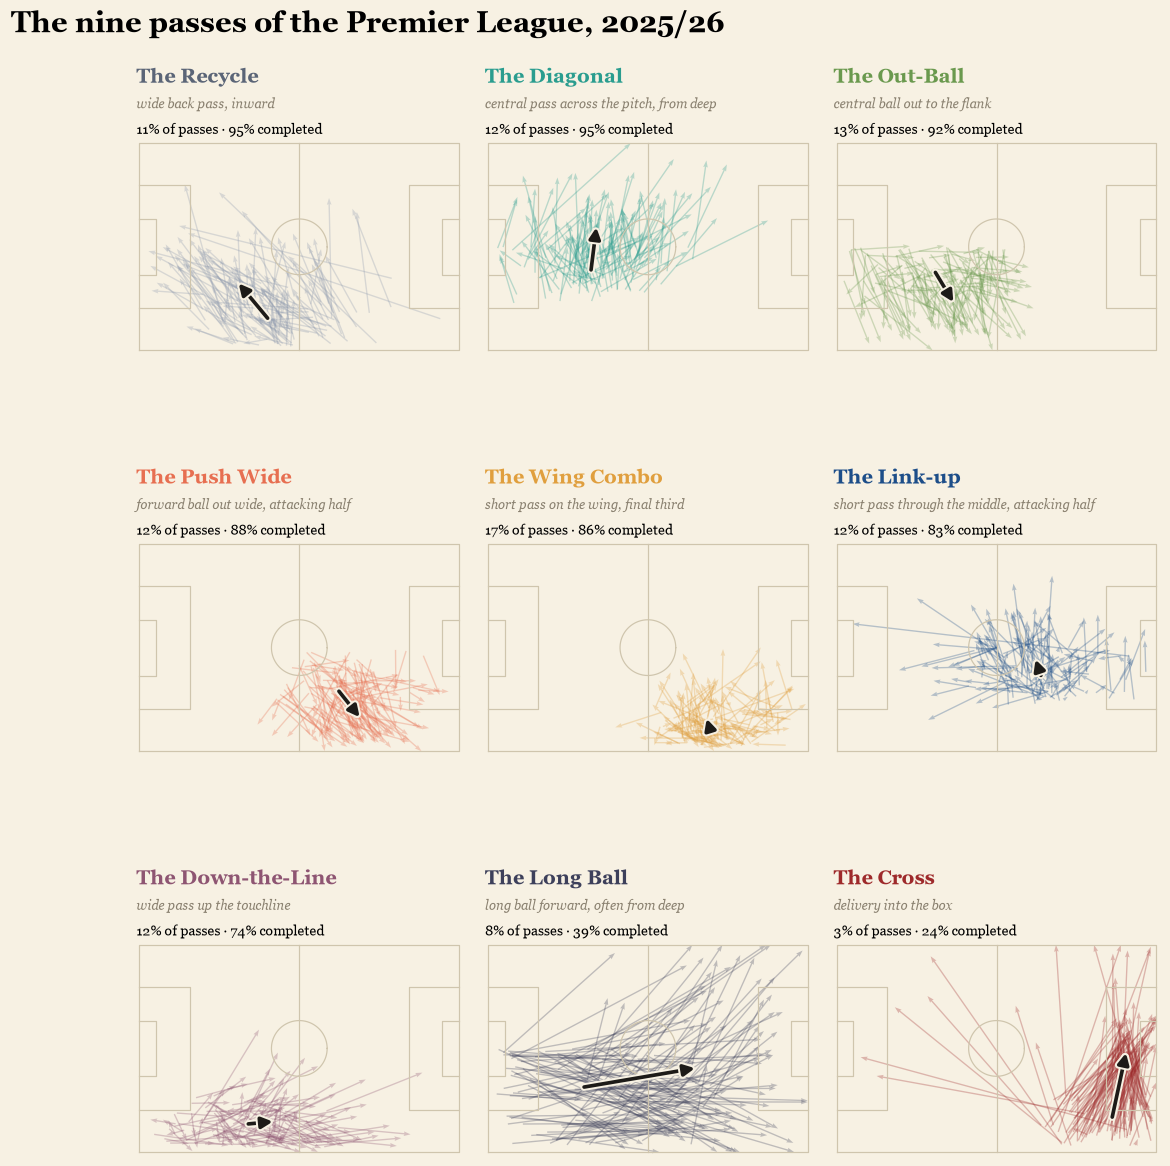

In [19]:
def pitch(ax, lw=0.8, col='#cfc5ad'):
    ax.set_xlim(-1, 106); ax.set_ylim(-1, 69); ax.set_aspect('equal'); ax.axis('off'); k = dict(color=col, lw=lw)
    ax.plot([0, 105, 105, 0, 0], [0, 0, 68, 68, 0], **k); ax.plot([52.5] * 2, [0, 68], **k)
    for x0, s in [(0, 1), (105, -1)]:
        ax.plot([x0, x0 + s * 16.5, x0 + s * 16.5, x0], [13.84, 13.84, 54.16, 54.16], **k); ax.plot([x0, x0 + s * 5.5, x0 + s * 5.5, x0], [24.84, 24.84, 43.16, 43.16], **k)
    t = np.linspace(0, 2 * np.pi, 80); ax.plot(52.5 + 9.15 * np.cos(t), 34 + 9.15 * np.sin(t), **k)

def atlas(season='2025-26', n=140):
    s = p[p.season == season]; order = nine.completion.sort_values(ascending=False).index          # safest to riskiest
    fig, axs = plt.subplots(3, 3, figsize=(12, 12.2)); fig.subplots_adjust(hspace=0.55, wspace=0.07, top=0.9)
    for ax, c in zip(axs.ravel(), order):
        h = s[s.cl == c]; sm = h.sample(n, random_state=1); pitch(ax); y0 = 34 - sm.start_w
        ax.quiver(sm.start_x, y0, sm.dx, sm.dyf, angles='xy', scale_units='xy', scale=1, color=COL[c], alpha=.3, width=.0042, headwidth=3.4)
        ax.annotate('', xy=(h.start_x.median() + h.dx.median(), 34 - h.start_w.median() + h.dyf.median()), xytext=(h.start_x.median(), 34 - h.start_w.median()),
                    arrowprops=dict(arrowstyle='-|>', color=INK, lw=2.4, mutation_scale=15, path_effects=[pe.withStroke(linewidth=5, foreground=BG)]))
        ax.text(0, 1.27, NAME[c], transform=ax.transAxes, fontsize=13, fontweight='bold', color=COL[c] if c else '#5b6577'); ax.text(0, 1.15, DESC[c], transform=ax.transAxes, fontsize=8.5, color=MUTE, style='italic')
        ax.text(0, 1.03, f'{len(h) / len(s) * 100:.0f}% of passes · {h.ok.mean() * 100:.0f}% completed', transform=ax.transAxes, fontsize=9)
    fig.suptitle(f'The nine passes of the Premier League, {season.replace("-", "/")}', fontsize=19, fontweight='bold', x=0.03, ha='left'); plt.show()
atlas('2025-26')

## 6. From passes to players

Each **player-season** (with at least 500 open-play passes) becomes a vector of nine shares: the share of his passes in each type. First the player-by-match table from the raw files (name, position string, team, minutes). **Needs the raw data**; cached after the first run.

In [20]:
def scan_players(season):
    rows = []
    for d in sorted((RAW / season).glob('*__*')):
        f = d / 'raw.json'
        if not f.exists(): continue
        raw = json.loads(f.read_text(encoding='utf-8')); gid = int(d.name.split('__')[1]); maxm = raw.get('expandedMaxMinute') or raw.get('maxMinute')
        for side in ('home', 'away'):
            for q in raw[side]['players']:
                st = 0 if q.get('isFirstEleven') else q.get('subbedInExpandedMinute')
                if st is None: continue
                en = q.get('subbedOutExpandedMinute')
                rows.append((gid, season, q['playerId'], q['name'], q.get('position'), raw[side]['teamId'], raw[side]['name'], float((maxm if en is None else en) - st)))
    return pd.DataFrame(rows, columns=['game_id', 'season', 'player_id', 'name', 'pos', 'team_id', 'team', 'minutes'])
fp = CACHE / 'player_matches.parquet'
if fp.exists(): pm = pd.read_parquet(fp)
else:
    t0 = time.time(); pm = pd.concat([scan_players(s) for s in SEASONS], ignore_index=True); pm.to_parquet(fp); print(f'scanned in {time.time() - t0:.0f}s')
print(f'{len(pm):,} player-match rows, {pm.player_id.nunique():,} players'); display(pm.head(3))

142,378 player-match rows, 2,456 players


,game_id,season,player_id,name,pos,team_id,team,minutes
0,719846,2013-14,73379,Wojciech Szczesny,GK,13,Arsenal,100.000
1,719846,2013-14,19471,Bacary Sagna,DR,13,Arsenal,98.000
2,719846,2013-14,30051,Laurent Koscielny,DC,13,Arsenal,100.000


In [21]:
ROLE = {'GK': 'GK', 'DC': 'DEF', 'DL': 'DEF', 'DR': 'DEF', 'DML': 'DEF', 'DMR': 'DEF', 'DMC': 'MID', 'MC': 'MID', 'AMC': 'MID', 'AML': 'WIDE', 'AMR': 'WIDE', 'ML': 'WIDE', 'MR': 'WIDE', 'FW': 'FW', 'FWL': 'FW', 'FWR': 'FW'}
POS = {'DC': 'centre-back', 'DR': 'right-back', 'DL': 'left-back', 'DMC': 'defensive midfielder', 'MC': 'central midfielder', 'DMR': 'right wing-back', 'DML': 'left wing-back', 'AMC': 'attacking midfielder',
       'AMR': 'right winger', 'AML': 'left winger', 'MR': 'right midfielder', 'ML': 'left midfielder', 'FW': 'forward', 'FWR': 'right forward', 'FWL': 'left forward', 'GK': 'goalkeeper'}
st = pm[pm.pos.notna() & (pm.pos != 'Sub')].copy(); st['role'] = st.pos.map(ROLE)
role_s = st.dropna(subset=['role']).groupby(['player_id', 'season']).role.agg(lambda s: s.mode().iat[0])         # main role among matches he started
role_c = st.dropna(subset=['role']).groupby('player_id').role.agg(lambda s: s.mode().iat[0])                       # career fallback
fine = st.groupby(['player_id', 'season']).pos.agg(lambda s: s.mode().iat[0]).rename('fine')
team = pm.groupby(['player_id', 'season']).team.agg(lambda s: s.mode().iat[0]).rename('team')
mins = pm.groupby(['player_id', 'season']).minutes.sum().rename('minutes'); pname = pm.groupby('player_id').name.last()

pp = p.dropna(subset=['player_id']).copy(); pp['player_id'] = pp.player_id.astype('int64')
ct = pd.crosstab([pp.player_id, pp.season], pp.cl); ct.columns = range(9); n_all = ct.sum(1)
def table(min_passes, seasons=None):
    keep = n_all[n_all >= min_passes]
    if seasons is not None: keep = keep[keep.index.get_level_values('season').isin(seasons)]
    sh = ct.loc[keep.index].div(keep, axis=0); sh.columns = [f'share_{c}' for c in range(9)]
    D = sh.reset_index(); D['n_passes'] = keep.values
    D['role'] = [role_s.get((a, b), role_c.get(a, np.nan)) for a, b in zip(D.player_id, D.season)]
    D = D.merge(fine.reset_index(), on=['player_id', 'season'], how='left').merge(team.reset_index(), on=['player_id', 'season'], how='left').merge(mins.reset_index(), on=['player_id', 'season'], how='left')
    D['name'] = D.player_id.map(pname); return D

S = table(500, seasons=[s for s in SEASONS if s != '2026-27'] + ['2026-27'])
print(f'{len(S):,} player-seasons with 500+ passes'); print(S.role.value_counts().to_dict()); display(S.head(3))

3,555 player-seasons with 500+ passes
{'DEF': 1524, 'MID': 1109, 'WIDE': 368, 'FW': 331, 'GK': 223}


,player_id,season,share_0,share_1,share_2,share_3,share_4,share_5,share_6,share_7,share_8,n_passes,role,fine,team,minutes,name
0,17,2013-14,0.070,0.116,0.060,0.192,0.019,0.205,0.148,0.082,0.108,2201,MID,MC,Liverpool,"3,110.000",Steven Gerrard
1,17,2014-15,0.068,0.122,0.069,0.180,0.010,0.215,0.151,0.074,0.110,1486,MID,MC,Liverpool,"2,456.000",Steven Gerrard
2,48,2013-14,0.082,0.210,0.067,0.129,0.010,0.143,0.190,0.077,0.092,1022,MID,DMC,Chelsea,"1,844.000",Frank Lampard


### 6.1 Is a player's mix a stable trait, or noise?
**Split-half reliability.** Split each player-season's matches into two alternating halves (by date), build the nine shares from each half, and correlate across players. High correlation means the mix is a repeatable property of the player, not sampling noise. (Spearman-Brown corrects the half-length correlation back up to a full season.)

In [22]:
sc = [f'share_{c}' for c in range(9)]
ppx = pp.merge(S[['player_id', 'season']], on=['player_id', 'season'])
gm = ppx[['player_id', 'season', 'game_id', 'date']].drop_duplicates().sort_values(['player_id', 'season', 'date', 'game_id']); gm['half'] = gm.groupby(['player_id', 'season']).cumcount() % 2
ppx = ppx.merge(gm[['player_id', 'season', 'game_id', 'half']], on=['player_id', 'season', 'game_id'])
idx = S.set_index(['player_id', 'season']).index
def half(h):
    c = pd.crosstab([ppx[ppx.half == h].player_id, ppx[ppx.half == h].season], ppx[ppx.half == h].cl).reindex(idx).fillna(0); c.columns = range(9); return c.div(c.sum(1), axis=0).to_numpy()
HA, HB = half(0), half(1)
r = np.array([np.corrcoef(HA[:, c], HB[:, c])[0, 1] for c in range(9)])
display(pd.DataFrame({'half vs half r': r, 'full-season reliability': 2 * r / (1 + r)}, index=NAME).T)

,The Recycle,The Link-up,The Wing Combo,The Diagonal,The Cross,The Out-Ball,The Push Wide,The Down-the-Line,The Long Ball
half vs half r,0.903,0.958,0.967,0.958,0.929,0.967,0.934,0.925,0.977
full-season reliability,0.949,0.978,0.983,0.979,0.963,0.983,0.966,0.961,0.989


### 6.2 How much is just position?
Share of the between-player variance that the main starting position explains, and whether what is left within a position is still reliable (so it is not noise).

In [23]:
k_ = S.role.notna().to_numpy(); Sx = S[k_]; R_ = Sx.role.to_numpy(); rows = []
for c in range(9):
    s_ = Sx[sc[c]]; res = s_ - s_.groupby(R_).transform('mean'); r2 = 1 - res.var(ddof=0) / s_.var(ddof=0)
    ra = pd.Series(HA[k_, c]) - pd.Series(HA[k_, c]).groupby(R_).transform('mean'); rb = pd.Series(HB[k_, c]) - pd.Series(HB[k_, c]).groupby(R_).transform('mean'); rw = np.corrcoef(ra, rb)[0, 1]
    rows.append((NAME[c], r2, 2 * rw / (1 + rw)))
display(pd.DataFrame(rows, columns=['pass type', 'R2: explained by position', 'reliability of what is left within position']).set_index('pass type'))
tot = (Sx[sc] - Sx[sc].mean()).pow(2).sum().sum(); res = (Sx[sc] - Sx.groupby('role')[sc].transform('mean')).pow(2).sum().sum()
print(f'position explains {1 - res / tot:.2f} of the total variance of the share vectors')
print('mean share (%) by role:'); display((Sx.groupby('role')[sc].mean() * 100).set_axis(NAME, axis=1).round(1))

,R2: explained by position,reliability of what is left within position
pass type,,
The Recycle,0.535,0.891
The Link-up,0.752,0.913
The Wing Combo,0.389,0.972
The Diagonal,0.321,0.968
The Cross,0.264,0.950
The Out-Ball,0.413,0.971
The Push Wide,0.704,0.885
The Down-the-Line,0.667,0.883
The Long Ball,0.737,0.957


position explains 0.53 of the total variance of the share vectors
mean share (%) by role:


,The Recycle,The Link-up,The Wing Combo,The Diagonal,The Cross,The Out-Ball,The Push Wide,The Down-the-Line,The Long Ball
role,,,,,,,,,
DEF,14.300,5.100,15.400,13.300,2.900,13.000,7.400,19.800,8.900
FW,7.500,25.100,30.400,3.400,4.600,3.600,15.500,6.800,3.100
GK,0.000,0.000,0.000,24.000,0.000,32.500,0.000,1.100,42.500
MID,8.300,16.700,15.400,10.500,2.000,12.900,18.100,9.900,6.200
WIDE,10.400,16.000,33.200,3.800,7.300,3.600,11.400,9.800,4.600


**Reading it.** A player's mix is a stable trait (reliability about 0.95 to 0.99). Position explains about half of how players differ; what is left within position is still highly reliable, so roughly half of the differences between players are **not** position and **not** noise. That does not prove it is skill: footedness, side of the pitch, team style and era all feed in.

**Goalkeepers** play only three of the nine types (about 42% long forward ball, 33% out-ball, 24% diagonal), so in a mixed comparison they dominate those shares. From here on they are analysed separately or left out.

**A sanity read:** who has the biggest share of each type in 2024/25?

In [24]:
o = S[(S.season == '2024-25') & (S.n_passes >= 1000)]
for c in range(9):
    t = o.sort_values(sc[c], ascending=False).head(3); print(f'{NAME[c]:<20}', ' | '.join(f"{r['name']} ({r.role}) {r[sc[c]] * 100:.0f}%" for _, r in t.iterrows()))

The Recycle          Pervis Estupiñán (DEF) 24% | Matt Doherty (DEF) 23% | Lucas Digne (DEF) 23%
The Link-up          Mateo Kovacic (MID) 30% | Cole Palmer (MID) 27% | Ilkay Gündogan (MID) 26%
The Wing Combo       Mohamed Salah (WIDE) 46% | Antoine Semenyo (WIDE) 45% | Matheus Nunes (DEF) 42%
The Diagonal         Tosin Adarabioyo (DEF) 32% | Bernd Leno (GK) 31% | Jan Bednarek (DEF) 30%
The Cross            Antonee Robinson (DEF) 10% | Tyrick Mitchell (DEF) 9% | Vitalii Mykolenko (DEF) 9%
The Out-Ball         Bernd Leno (GK) 46% | Bart Verbruggen (GK) 45% | André Onana (GK) 45%
The Push Wide        Mateo Kovacic (MID) 26% | Sander Berge (MID) 25% | Martin Ødegaard (MID) 24%
The Down-the-Line    Lewis Hall (DEF) 33% | Tino Livramento (DEF) 27% | Ola Aina (DEF) 27%
The Long Ball        Jordan Pickford (GK) 45% | Robert Sánchez (GK) 36% | Mark Flekken (GK) 33%


## 7. A similar-player search

Given a player-season, list the outfield player-seasons with the closest mix. Which distance? Two tests: (a) given one half of a player's matches, how often is the *other half of the same player* the nearest of all other halves; (b) is the nearest player-season in a different season the same player?

In [25]:
keep_o = (S.role != 'GK').to_numpy(); O = S[keep_o].reset_index(drop=True); X0 = O[sc].to_numpy()
A_, B_ = HA[keep_o], HB[keep_o]; pid, ssn = O.player_id.to_numpy(), O.season.to_numpy(); mu_s, sd_s = X0.mean(0), X0.std(0)
metrics = {'raw Euclidean': lambda a: a, 'Hellinger (sqrt of shares)': np.sqrt, 'z-scored shares': lambda a: (a - mu_s) / sd_s}
rows = []
for nm, f in metrics.items():
    Dm = cdist(f(A_), f(B_)); rank = (Dm < np.diag(Dm)[:, None]).sum(1) + 1
    F = f(X0); D2 = cdist(F, F); D2[ssn[:, None] == ssn[None, :]] = np.inf; nn = D2.argmin(1)
    has = np.array([((pid == pid[i]) & (ssn != ssn[i])).any() for i in range(len(pid))])
    rows.append((nm, (rank == 1).mean(), np.median(rank), (pid[nn] == pid)[has].mean()))
display(pd.DataFrame(rows, columns=['distance', 'own other half is nearest', 'median rank of own half', 'nearest other-season row is the same player']).set_index('distance'))
print(f'chance of being nearest: {1 / len(O):.4f}; chance median rank: about {len(O) // 2}')

,own other half is nearest,median rank of own half,nearest other-season row is the same player
distance,,,
raw Euclidean,0.107,18.000,0.130
Hellinger (sqrt of shares),0.123,14.000,0.156
z-scored shares,0.108,16.000,0.135


chance of being nearest: 0.0003; chance median rank: about 1666


**Reading it.** Hellinger distance (Euclidean on square roots of the shares) is best. The honest reading: **the tool gives a shortlist, not a twin.** The true match is the very nearest only about one time in eight, though its median rank is about 14 of 3,300. With nine shares many players of the same type sit close together.

The noise scale: the distance between a player-season's own two halves, rescaled to two full seasons. Neighbours closer than that are indistinguishable from sampling noise.

In [26]:
Dh = np.sqrt(((np.sqrt(A_) - np.sqrt(B_)) ** 2).sum(1)); noise = np.median(Dh) / np.sqrt(2); print(f'noise scale (Hellinger, two full seasons): {noise:.3f}')
def similar(name, season, k=6, same_season=True):
    q = O[(O.name.str.lower().str.contains(name.lower())) & (O.season == season)]
    if len(q) != 1: return f'{len(q)} matches'
    q = q.iloc[0]; C = O[(O.player_id != q.player_id) & ((O.season == season) if same_season else True)].copy()
    C['dist'] = np.sqrt(((np.sqrt(C[sc].to_numpy()) - np.sqrt(q[sc].to_numpy(float))) ** 2).sum(1)); C = C.sort_values('dist').drop_duplicates('player_id').head(k)
    C['within noise'] = C.dist <= noise; return C[['name', 'season', 'role', 'team', 'dist', 'within noise']]
for nm in ('Declan Rice', 'Alexander-Arnold'): print(nm); display(similar(nm, '2024-25'))

noise scale (Hellinger, two full seasons): 0.073
Declan Rice


,name,season,role,team,dist,within noise
3305,Mateus Fernandes,2024-25,MID,Southampton,0.072,True
3032,Enzo Fernández,2024-25,MID,Chelsea,0.080,False
2223,James Maddison,2024-25,MID,Tottenham,0.083,False
2838,Alexis Mac Allister,2024-25,MID,Liverpool,0.084,False
2823,Daichi Kamada,2024-25,MID,Crystal Palace,0.099,False
2811,Ryan Yates,2024-25,MID,Nottingham Forest,0.101,False


Alexander-Arnold


,name,season,role,team,dist,within noise
2961,Pedro Porro,2024-25,DEF,Tottenham,0.132,False
1940,Andy Robertson,2024-25,DEF,Liverpool,0.170,False
2505,James Justin,2024-25,DEF,Leicester,0.190,False
3230,Victor Kristiansen,2024-25,DEF,Leicester,0.204,False
3185,Mikkel Damsgaard,2024-25,MID,Brentford,0.207,False
1033,Aaron Cresswell,2024-25,DEF,West Ham,0.212,False


## 8. Adding value: pass xT

A profile says what someone does, not how much it adds. **xT (expected threat)** values a completed pass by how much it moves the ball into more dangerous areas: xT(end cell) minus xT(start cell) on a 12 x 8 grid, zero for failed passes. I chose xT over VAEP because it repeats far better (split-half reliability at 20 matches: 0.87 for xT against 0.39 for VAEP per 90 in a trust test on this data).

The grid was fitted on the 6.76 million actions **before 2024/25** with a Markov model of shots, goals and moves (a short code reference is in the README); it is stored in `data/xt_grid_pre2024.csv`. So xT for 2024/25 onward is out of sample; for earlier seasons the grid has seen the same data (mildly flattering), so compare xT *within* a season.

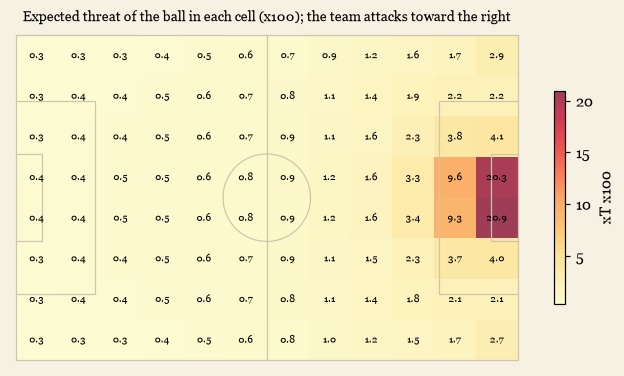

In [27]:
fig, ax = plt.subplots(figsize=(7.5, 4.2)); pitch(ax); im = ax.imshow(grid * 100, extent=[0, 105, 68, 0], cmap='YlOrRd', alpha=.75, aspect='equal', origin='upper'); ax.set_ylim(69, -1)
for i in range(8):
    for j in range(12): ax.text((j + .5) * 105 / 12, (i + .5) * 68 / 8, f'{grid[i, j] * 100:.1f}', ha='center', va='center', fontsize=6.5)
ax.set_title('Expected threat of the ball in each cell (x100); the team attacks toward the right', fontsize=9); plt.colorbar(im, shrink=.6, label='xT x100'); plt.show()

In [28]:
xt_sum = p.dropna(subset=['player_id']).assign(player_id=lambda d: d.player_id.astype('int64')).groupby(['player_id', 'season']).xt.sum().rename('xt_sum')
V = S.merge(xt_sum.reset_index(), on=['player_id', 'season'], how='left')
V['xt90'] = V.xt_sum / V.minutes * 9000; V.loc[V.minutes < 900, 'xt90'] = np.nan                    # per 90 minutes, x100 = goals per 100 matches; needs 900+ minutes
S['xt90'] = V['xt90'].to_numpy()
print(f"pass xT per 90 available for {V.xt90.notna().mean():.0%} of player-seasons"); display(V.groupby('role').xt90.describe()[['count', 'mean', '50%']].round(2))

pass xT per 90 available for 99% of player-seasons


,count,mean,50%
role,,,
DEF,"1,494.000",6.180,5.410
FW,330.000,4.540,3.720
GK,223.000,2.200,2.120
MID,"1,089.000",5.620,4.840
WIDE,368.000,7.940,7.600


### 8.1 Is pass xT a stable measure of a player?
Split-half reliability of passes per 90 and xT per 90 (2024/25 and 2025/26, 900+ minutes), and how much of a player's xT per pass is just his *mix* (the average value of each type times his shares).

In [29]:
q = p.dropna(subset=['player_id']).copy(); q['player_id'] = q.player_id.astype('int64'); q = q[(q.season >= '2024-25') & (q.season <= '2025-26')]
q = q.merge(gm[['player_id', 'season', 'game_id', 'half']], on=['player_id', 'season', 'game_id'], how='inner')
mm = pm.groupby(['player_id', 'season', 'game_id']).minutes.sum().rename('mn').reset_index()
def hres(h):
    d = q[q.half == h].groupby(['player_id', 'season']).agg(n=('ok', 'size'), xt=('xt', 'sum')); mn = mm.merge(gm[gm.half == h][['player_id', 'season', 'game_id']], on=['player_id', 'season', 'game_id']).groupby(['player_id', 'season']).mn.sum()
    return pd.DataFrame({'passes90': d.n / mn * 90, 'xt90': d.xt / mn * 9000})
H0, H1 = hres(0), hres(1); ok_ = V[(V.season >= '2024-25') & (V.season <= '2025-26') & (V.minutes >= 900) & (V.role != 'GK')].set_index(['player_id', 'season']).index
rows = []
for m_ in ('passes90', 'xt90'):
    rr = np.corrcoef(H0.reindex(ok_)[m_], H1.reindex(ok_)[m_])[0, 1]; rows.append((m_, rr, 2 * rr / (1 + rr)))
display(pd.DataFrame(rows, columns=['metric', 'half vs half r', 'full-season reliability']).set_index('metric'))
cl_xt = p[p.season >= '2024-25'].groupby('cl').xt.mean(); W = V[(V.season >= '2024-25') & V.xt_sum.notna() & (V.role != 'GK') & (V.minutes >= 900)]
exp = (W[sc].to_numpy() * cl_xt.to_numpy()).sum(1) * 100; act = W.xt_sum / W.n_passes * 100
print(f"expected xT per pass from the mix alone explains {np.corrcoef(exp, act)[0, 1] ** 2:.2f} of the variance of actual xT per pass ({len(W)} player-seasons)")

,half vs half r,full-season reliability
metric,,
passes90,0.889,0.941
xt90,0.669,0.802


expected xT per pass from the mix alone explains 0.69 of the variance of actual xT per pass (496 player-seasons)


**Reading it.** Pass xT per 90 repeats well (about 0.8), and about 70% of a player's xT per pass is explained by his mix alone; the rest is partly noise and partly what he does with the same kind of pass.

**Limits.** Pass xT only counts how much *completed passes* move the ball: it ignores carrying, winning the ball and positioning, so a low pass xT does not mean a poor player (an all-rounder like Declan Rice sits below the midfield average on this measure). The project stays about passing on purpose.

## 9. Role drift: how much does a player's passing change?

Distance between a player's own mix k seasons apart (square-root-share space). Reference points: sampling noise for two full seasons (from Part 7), and the distance between two random different players of the same role and season.

In [30]:
O['si'] = O.season.map({s: i for i, s in enumerate(SEASONS)}); RS = np.sqrt(O[sc].to_numpy()); rc_ = [f'r{c}' for c in range(9)]; O[rc_] = RS
ac_ = [f'a{c}' for c in range(9)]; O[ac_] = O[rc_] - O.groupby(['season', 'role'])[rc_].transform('mean').to_numpy()     # peer-adjusted: season-and-role average removed
j = O.merge(O, on='player_id', suffixes=('', '_b')); j = j[j.si_b > j.si].copy(); j['lag'] = j.si_b - j.si
j['dist'] = np.sqrt(((j[rc_].to_numpy() - j[[c + '_b' for c in rc_]].to_numpy()) ** 2).sum(1))
j['dist_adj'] = np.sqrt(((j[ac_].to_numpy() - j[[c + '_b' for c in ac_]].to_numpy()) ** 2).sum(1))
rng = np.random.default_rng(0); base = []
for (s, r), g_ in O.groupby(['season', 'role']):
    if len(g_) < 10: continue
    a_, b_ = rng.integers(0, len(g_), (2, 300)); okp = g_.player_id.to_numpy()[a_] != g_.player_id.to_numpy()[b_]
    base.append(np.sqrt(((g_[rc_].to_numpy()[a_[okp]] - g_[rc_].to_numpy()[b_[okp]]) ** 2).sum(1)))
print(f'sampling noise {noise:.3f} | two random players of the same role and season {np.concatenate(base).mean():.3f}')
display(j[j.lag <= 6].groupby('lag').agg(pairs=('dist', 'size'), raw_distance=('dist', 'mean'), peer_adjusted_distance=('dist_adj', 'mean')).T)
j1 = j[j.lag == 1].copy(); j1['club'] = np.where(j1.team == j1.team_b, 'same club', 'new club'); j1['role_change'] = np.where(j1.role == j1.role_b, 'same role', 'role label changed')
print('one season apart, peer-adjusted distance (league-wide and position differences removed):'); display(j1.groupby(['club', 'role_change']).dist_adj.agg(pairs='size', mean='mean', median='median'))

sampling noise 0.073 | two random players of the same role and season 0.274


lag,1,2,3,4,5,6
pairs,"1,929.000","1,404.000","1,018.000",705.000,485.000,310.000
raw_distance,0.120,0.141,0.155,0.174,0.190,0.199
peer_adjusted_distance,0.133,0.150,0.164,0.179,0.191,0.195


one season apart, peer-adjusted distance (league-wide and position differences removed):


pairs  mean  median
club      role_change                            
new club  role label changed     32 0.258   0.246
          same role             152 0.152   0.134
same club role label changed    172 0.249   0.252
          same role            1573 0.116   0.103

**Reading it.** A player is much closer to his own earlier self than to a random peer, but he drifts steadily, and even one season of change is well above noise. After removing league-wide and position differences (peer-adjusted), a change of role label roughly doubles the one-season drift and a club change adds about a third.

**Are the biggest shifts real position changes?** Compare the 12 biggest one-season shifts with the finer position strings (DC = centre-back, DR/DL = full-back, and so on).

In [31]:
fp_ = fine.reset_index(); top = j1.sort_values('dist_adj', ascending=False).head(12)
def fpos(pid, s): v = fp_[(fp_.player_id == pid) & (fp_.season == s)].fine; return v.iat[0] if len(v) else None
out = pd.DataFrame({'player': top.name, 'from': top.season, 'to': top.season_b, 'main position before': [fpos(a, b) for a, b in zip(top.player_id, top.season)], 'main position after': [fpos(a, b) for a, b in zip(top.player_id, top.season_b)], 'distance': top.dist_adj}).reset_index(drop=True)
out['position changed'] = out['main position before'] != out['main position after']; display(out); print('position changed in', int(out['position changed'].sum()), 'of 12')
dd = j1[(j1.role == 'DEF') & (j1.role_b == 'DEF')].sort_values('dist_adj', ascending=False)
sw_ = lambda d: np.mean([(lambda a, b: a is not None and b is not None and ((a == 'DC') != (b == 'DC')))(fpos(x, s), fpos(x, t)) for x, s, t in zip(d.player_id, d.season, d.season_b)])
print(f'defender-to-defender pairs where the main position switches between centre-back and full-back: biggest 100 shifts {sw_(dd.head(100)):.0%}, smallest 100 {sw_(dd.tail(100)):.0%}')

,player,from,to,main position before,main position after,distance,position changed
0,Ben White,2021-22,2022-23,DC,DR,0.582,True
1,Marcos Rojo,2015-16,2016-17,DL,DC,0.560,True
2,Calum Chambers,2020-21,2021-22,DR,DC,0.556,True
3,Michail Antonio,2015-16,2016-17,DR,DMR,0.550,True
4,Dan Burn,2020-21,2021-22,DL,DC,0.511,True
5,Axel Tuanzebe,2024-25,2025-26,DR,DC,0.509,True
6,Kristoffer Ajer,2024-25,2025-26,DR,DC,0.502,True
7,Pascal Struijk,2021-22,2022-23,DC,DL,0.500,True
8,Fabian Delph,2018-19,2019-20,DL,MC,0.479,True
9,Joe Gomez,2017-18,2018-19,DR,DC,0.463,True


position changed in 11 of 12


defender-to-defender pairs where the main position switches between centre-back and full-back: biggest 100 shifts 36%, smallest 100 1%


**Reading it.** Almost all of the biggest shifts are real position changes (for example Ben White from centre-back to right-back), and among defenders the pass mix picks up a centre-back or full-back switch even where the coarse label "defender" says nothing changed.

## 10. Player k-means by position, pooled over 13 seasons

This is the original idea I set out to imitate (k-means on **players**, coloured by group, with names), but rebuilt on the nine pass types and with the checks the original lacked.

**Design.**
- Players are grouped *within position*: defenders, midfielders, and attackers (wide players and forwards). Goalkeepers are left out.
- One clustering per position over **all seasons pooled**, so a group means the same thing in every season and a player can *move* between groups over time.
- **Each position gets its own pass cutoff** (10.1) and its own number of groups (10.2). Attackers pass far less than defenders and midfielders, so a flat cutoff throws away half of them.
- **Two levels:** a few *types* that are stable enough to draw conclusions from, and more *styles* that are finer but fuzzier (10.3).
- The current season (2026/27, only 8 matches per team old) is assigned afterwards to the nearest group, for players with 200+ passes.

### 10.1 A pass cutoff for each position
A player-season is only usable if his nine shares are measured reliably. I rebuilt the player table with a low floor (150 passes) and measured **split-half reliability** (odd matches against even matches, Spearman-Brown corrected, mean of the nine shares) inside 100-pass windows, within position.

In [32]:
from scipy.optimize import linear_sum_assignment
GROUPS = {'DEF': 'Defenders', 'MID': 'Midfielders', 'ATT': 'Attackers (wide players and forwards)'}
PTN = ['Recycle', 'Link-up', 'Wing Combo', 'Diagonal', 'Cross', 'Out-Ball', 'Push Wide', 'Down-the-Line', 'Long Ball']
S2 = table(150, seasons=[s for s in SEASONS if s != '2026-27'])
S2['grp'] = np.where(S2.role == 'GK', 'GK', np.where(S2.role == 'DEF', 'DEF', np.where(S2.role == 'MID', 'MID', 'ATT')))
S2 = S2.merge(xt_sum.reset_index(), on=['player_id', 'season'], how='left'); S2['xt90'] = S2.xt_sum / S2.minutes * 9000; S2.loc[S2.minutes < 900, 'xt90'] = np.nan
S2['p90'] = S2.n_passes / S2.minutes * 90
gm = pp[['player_id', 'season', 'game_id', 'date']].drop_duplicates().sort_values(['player_id', 'season', 'date', 'game_id']); gm['half'] = gm.groupby(['player_id', 'season']).cumcount() % 2
q = pp.merge(gm[['player_id', 'season', 'game_id', 'half']], on=['player_id', 'season', 'game_id']); idx2 = pd.MultiIndex.from_frame(S2[['player_id', 'season']])
HALF = [pd.crosstab([d.player_id, d.season], d.cl).reindex(idx2).fillna(0).to_numpy() for _, d in q.groupby('half')]; del q, gm
def rel(m):                      # mean split-half reliability of the nine shares for the rows in mask m
    A, B = [h[m] / h[m].sum(1, keepdims=True) for h in HALF]; r = np.array([np.corrcoef(A[:, c], B[:, c])[0, 1] for c in range(9)]); return np.nanmean(2 * r / (1 + r))
print('median open-play passes per 90 minutes:', S2[S2.grp.isin(GROUPS)].groupby('grp').p90.median().round(0).to_dict())
rows = []
for lo in range(150, 551, 50):
    row = {'passes from': lo}
    for g_ in GROUPS:
        m = ((S2.grp == g_) & (S2.n_passes >= lo) & (S2.n_passes < lo + 100)).to_numpy(); row[g_ + ' n'] = int(m.sum()); row[g_ + ' reliability'] = rel(m)
    rows.append(row)
print('reliability of the nine shares for player-seasons with lo to lo+100 passes:'); display(pd.DataFrame(rows).set_index('passes from').round(2))

median open-play passes per 90 minutes: {'ATT': 27.0, 'DEF': 40.0, 'MID': 43.0}
reliability of the nine shares for player-seasons with lo to lo+100 passes:


,DEF n,DEF reliability,MID n,MID reliability,ATT n,ATT reliability
passes from,,,,,,
150,157,0.760,106,0.670,251,0.720
200,138,0.850,105,0.680,226,0.760
250,139,0.840,108,0.710,198,0.770
300,137,0.850,109,0.760,198,0.790
350,126,0.880,114,0.800,186,0.820
400,153,0.890,99,0.820,178,0.840
450,173,0.900,86,0.850,163,0.830
500,161,0.900,85,0.830,138,0.850
550,143,0.920,80,0.820,141,0.870


**Reading it.** Reliability climbs with the number of passes in every position. A strict bar of 0.80 for every 100-pass window would put the cutoff at 200 for defenders and 350 for midfielders and attackers. That throws away many players, so I **relaxed it to a floor of about 0.70 to 0.75**: **150 passes for defenders (the lowest I measured), 250 for midfielders and 250 for attackers**. Midfielders' mixes are the least distinct, so they need more passes for the same reliability. The price is noisier players at the margin: the 100 passes just above each cutoff have reliability of about 0.76 (defenders), 0.71 (midfielders) and 0.77 (attackers), against 0.85 or more for full-volume players. The stability checks in 10.2 were run at these cutoffs.

In [33]:
CUTS = {'DEF': 150, 'MID': 250, 'ATT': 250}
tab = []
for g_ in GROUPS:
    d = S2[S2.grp == g_]; tab.append(dict(position=GROUPS[g_].split(' (')[0], kept_at_500=int((d.n_passes >= 500).sum()), pct_kept_at_500=round(100 * (d.n_passes >= 500).mean()), cutoff=CUTS[g_], kept_at_cutoff=int((d.n_passes >= CUTS[g_]).sum()), reliability_at_cutoff=round(rel((S2.grp == g_).to_numpy() & (S2.n_passes >= CUTS[g_]).to_numpy()), 3)))
display(pd.DataFrame(tab).set_index('position'))

,kept_at_500,pct_kept_at_500,cutoff,kept_at_cutoff,reliability_at_cutoff
position,,,,,
Defenders,1517,75,150,2026,0.910
Midfielders,1107,75,250,1367,0.869
Attackers,699,49,250,1175,0.854


**Reading it.** A flat 500-pass cutoff kept three quarters of defenders and midfielders but only about half of the attackers, who simply pass less. With a cutoff per position I keep about 34% more defenders, 23% more midfielders and 68% more attackers, and overall reliability stays at 0.85 to 0.91 (against 0.89 to 0.94 at 500). Attackers still have the fewest rows because there are fewer of them.

### 10.2 How many groups? A sweep per position
For each position, at its own cutoff, k from 2 to 12 with five checks:
- **silhouette** (how separate the groups are),
- **bootstrap stability**: ARI between two clusterings fitted on different 80% resamples, both predicting everyone,
- **half-vs-half agreement**: cluster on all matches, then assign each player's odd-match mix and even-match mix separately and compare (ARI). This is pessimistic because each half has half the passes,
- **era stability**: ARI between a clustering fitted on 2013/14-2019/20 and one on 2020/21 onward, both predicting everyone,
- **smallest group** as a share of the position.

In [34]:
fk = CACHE / 'k_sweep.csv'
if fk.exists(): SW = pd.read_csv(fk)
else:
    rng = np.random.default_rng(0); rows = []
    for g_ in GROUPS:
        msk = ((S2.grp == g_) & (S2.n_passes >= CUTS[g_])).to_numpy(); D = S2[msk].reset_index(drop=True); X = np.sqrt(D[sc].to_numpy())
        HA, HB = [np.sqrt(h[msk] / h[msk].sum(1, keepdims=True)) for h in HALF]; early = (D.season <= '2019-20').to_numpy()
        for k in range(2, 13):
            km_ = KMeans(k, n_init=20, random_state=0).fit(X); bs = []
            for b in range(20):
                i = rng.choice(len(X), int(.8 * len(X)), replace=False); jj = rng.choice(len(X), int(.8 * len(X)), replace=False)
                bs.append(ari(KMeans(k, n_init=5, random_state=b).fit(X[i]).predict(X), KMeans(k, n_init=5, random_state=b + 100).fit(X[jj]).predict(X)))
            rows.append(dict(pos=g_, n=len(D), k=k, silhouette=silhouette_score(X, km_.labels_), bootstrap_ari=np.mean(bs), half_vs_half_ari=ari(km_.predict(HA), km_.predict(HB)),
                             era_ari=ari(KMeans(k, n_init=10, random_state=1).fit(X[early]).predict(X), KMeans(k, n_init=10, random_state=2).fit(X[~early]).predict(X)), smallest_group=np.bincount(km_.labels_).min() / len(X)))
    SW = pd.DataFrame(rows); SW.to_csv(fk, index=False)
for g_ in GROUPS: print(GROUPS[g_], f'({int(SW[SW.pos == g_].n.iloc[0]):,} player-seasons, cutoff {CUTS[g_]} passes)'); display(SW[SW.pos == g_].drop(columns=['pos', 'n']).set_index('k').round(2))

Defenders (2,026 player-seasons, cutoff 150 passes)


,silhouette,bootstrap_ari,half_vs_half_ari,era_ari,smallest_group
k,,,,,
2,0.590,1.000,0.880,0.990,0.490
3,0.410,0.990,0.830,0.960,0.150
4,0.250,0.930,0.680,0.670,0.150
5,0.220,0.750,0.640,0.430,0.140
6,0.200,0.840,0.520,0.440,0.100
7,0.190,0.890,0.500,0.500,0.080
8,0.190,0.720,0.480,0.420,0.060
9,0.180,0.640,0.440,0.430,0.050
10,0.170,0.660,0.430,0.460,0.040


Midfielders (1,367 player-seasons, cutoff 250 passes)


,silhouette,bootstrap_ari,half_vs_half_ari,era_ari,smallest_group
k,,,,,
2,0.340,0.920,0.650,0.860,0.400
3,0.210,0.960,0.540,0.620,0.260
4,0.200,0.820,0.470,0.390,0.190
5,0.180,0.830,0.450,0.310,0.140
6,0.170,0.680,0.410,0.350,0.120
7,0.160,0.600,0.360,0.330,0.110
8,0.160,0.640,0.360,0.340,0.090
9,0.150,0.660,0.350,0.400,0.070
10,0.150,0.600,0.340,0.350,0.070


Attackers (wide players and forwards) (1,175 player-seasons, cutoff 250 passes)


,silhouette,bootstrap_ari,half_vs_half_ari,era_ari,smallest_group
k,,,,,
2,0.330,0.980,0.700,0.790,0.490
3,0.210,0.930,0.560,0.650,0.300
4,0.200,0.900,0.490,0.430,0.190
5,0.180,0.860,0.440,0.520,0.170
6,0.170,0.870,0.420,0.520,0.130
7,0.150,0.690,0.400,0.410,0.100
8,0.150,0.580,0.380,0.390,0.100
9,0.140,0.620,0.350,0.390,0.080
10,0.140,0.520,0.350,0.340,0.080


**Reading it.**
- **Stability falls fast after k = 3 or 4 in every position.** Two groups is always the clearest split (for defenders it is just centre-backs against full-backs). By k = 6 or 7 the same player lands in the same group only about half the time when his odd and even matches are clustered separately, and early and late seasons find different groups.
- **A few k values beat their neighbours** on bootstrap stability: **k = 7 for defenders** (about 0.9), **k = 5 for midfielders** (about 0.83) and **k = 6 for attackers** (about 0.87). They are local peaks, not strong ones.
- The cutoff matters little for stability: moving from 200/350/350 to 150/250/250 changed these numbers by a few hundredths, except that the attackers' era agreement for types fell from 0.53 to 0.43.

So I keep two levels. The **types** (4 defenders, 3 midfielders, 4 attackers) are the largest k that is still clearly stable, and are what I draw conclusions from. The **styles** (7, 5, 6) are the local stability peaks: finer, more interesting, but their borders wobble. Read them as neighbourhoods on a continuum, not as hard categories.

### 10.3 Fit both levels and name the groups
The cluster numbers that k-means returns are arbitrary, so names are attached by rule: each group's average mix, in standard deviations from the position average, is matched to a written prototype (an optimal one-to-one assignment). The printed examples let you check the names by eye.

In [35]:
KSEL = {'DEF': 4, 'MID': 3, 'ATT': 4}; KFINE = {'DEF': 7, 'MID': 5, 'ATT': 6}
TYPE_NAMES = {
    'DEF': [('Overlapping full-backs', '#c8553d', 'Wing combinations, down-the-line balls and crosses from the touchline.'), ('Hybrid full-backs', '#e09f3e', 'Full-backs who recycle, combine and play more inside.'),
            ('Distributor centre-backs', '#1d4e89', 'Diagonals and out-balls from deep.'), ('Direct centre-backs', '#6b7a8f', 'Fewer diagonals, more down-the-line and long balls.')],
    'MID': [('Attacking creators', '#c8553d', 'Wing combinations and link-ups in the attacking half.'), ('Deep distributors', '#1d4e89', 'Out-balls and diagonals; push the ball forward and wide from deep.'),
            ('Balanced midfielders', '#2a9d8f', 'A mix of everything, with more down-the-line and long balls.')],
    'ATT': [('Combination wingers', '#c8553d', 'Mostly wing combinations: short passes on the wing in the final third.'), ('Link-up forwards', '#1d4e89', 'Link-up passes through the middle; low threat per 90.'),
            ('Crossing wide players', '#e09f3e', 'Crosses and down-the-line balls from wide.'), ('Inside creators', '#2a9d8f', 'Link-ups, pushes wide and wing combinations from inside positions.')]}
# finer styles: (name, colour, description, prototype = how the style differs from its position average, in the nine pass types)
STYLES = {
    'DEF': [('Overlapping full-backs', '#c8553d', 'The purest wing combiners: a third of their passes are wing combinations, plus crosses.', {'Wing Combo': 1, 'Cross': .3, 'Out-Ball': -.3}),
            ('Crossing full-backs', '#e09f3e', 'Down-the-line balls, wing combinations and crosses.', {'Down-the-Line': 1, 'Wing Combo': .5, 'Cross': .4, 'Long Ball': .3}),
            ('Inverted full-backs', '#b5838d', 'Recycle, link up and push wide from inside: full-backs who act like midfielders.', {'Recycle': 1, 'Link-up': 1, 'Push Wide': .8, 'Wing Combo': .3}),
            ('Wide centre-backs', '#6b7a8f', 'Centre-backs (or hybrids) whose passing goes down the line.', {'Down-the-Line': 1, 'Wing Combo': .2, 'Long Ball': .3, 'Recycle': .3}),
            ('Ball-progressing centre-backs', '#2a9d8f', 'Diagonals and out-balls, plus pushes wide and link-ups: they move the ball up.', {'Diagonal': .8, 'Out-Ball': .6, 'Push Wide': 1, 'Link-up': .6}),
            ('Diagonal centre-backs', '#1d4e89', 'A quarter diagonals and a quarter out-balls: the switchers.', {'Diagonal': 1, 'Out-Ball': 1, 'Wing Combo': -.5}),
            ('Direct centre-backs', '#7d5ba6', 'Out-balls with more long balls and fewer short passes.', {'Out-Ball': .8, 'Long Ball': 1, 'Diagonal': .5, 'Recycle': -.3})],
    'MID': [('Attacking creators', '#c8553d', 'Wing combinations and crosses in the attacking half.', {'Wing Combo': 1, 'Cross': .4, 'Out-Ball': -.5}),
            ('Link-up midfielders', '#e09f3e', 'Link-ups, wing combinations and pushes wide.', {'Link-up': 1, 'Wing Combo': .6, 'Push Wide': .4}),
            ('Deep circulators', '#1d4e89', 'Out-balls, diagonals, link-ups and pushes wide; few wing combinations.', {'Out-Ball': .7, 'Diagonal': .7, 'Link-up': .5, 'Push Wide': .5, 'Wing Combo': -.6}),
            ('Long-passing midfielders', '#7d5ba6', 'Out-balls, diagonals and long balls from deep.', {'Out-Ball': .8, 'Diagonal': .8, 'Long Ball': 1, 'Link-up': -.4}),
            ('All-round midfielders', '#2a9d8f', 'Close to the average midfielder, with a little more down-the-line.', {'Down-the-Line': .8, 'Recycle': .4, 'Long Ball': .3})],
    'ATT': [('Crossing wide players', '#e09f3e', 'Crosses and down-the-line balls from wide.', {'Cross': 1, 'Down-the-Line': .8, 'Long Ball': .5, 'Link-up': -.5}),
            ('Wing-combination wingers', '#c8553d', 'Over 40% wing combinations.', {'Wing Combo': 1, 'Recycle': .3, 'Link-up': -.4}),
            ('All-round wingers', '#6b7a8f', 'Close to the average wide player.', {'Recycle': .3, 'Down-the-Line': .3, 'Wing Combo': .2}),
            ('Roaming creators', '#2a9d8f', 'Pushes wide, out-balls and diagonals: attackers who drift and switch play.', {'Push Wide': 1, 'Out-Ball': .6, 'Diagonal': .6, 'Wing Combo': -.5}),
            ('Inside forwards', '#7d5ba6', 'Link-ups, wing combinations and pushes wide from inside.', {'Link-up': .8, 'Wing Combo': .6, 'Push Wide': .6}),
            ('Link-up strikers', '#1d4e89', 'A third of passes are link-ups through the middle.', {'Link-up': 1, 'Wing Combo': -.6, 'Recycle': -.4})]}
def name_clusters(gname, M):                      # core types. M: k x 9 mean shares; returns {cluster id: index into TYPE_NAMES[gname]}
    k = len(M); left = set(range(k)); out = {}
    def take(score, idx):
        c = max(left, key=score); out[c] = idx; left.discard(c)
    if gname == 'DEF':
        fb = sorted(range(k), key=lambda c: -M[c, 2])[:2]; cb = [c for c in range(k) if c not in fb]
        out[fb[0]] = 0; out[fb[1]] = 1; cb = sorted(cb, key=lambda c: -(M[c, 3] + M[c, 5])); out[cb[0]] = 2; out[cb[1]] = 3
    elif gname == 'MID':
        take(lambda c: M[c, 2], 0); take(lambda c: M[c, 5] + M[c, 3], 1); out[next(iter(left))] = 2
    else:
        take(lambda c: M[c, 2], 0); take(lambda c: M[c, 1], 1); take(lambda c: M[c, 4], 2); out[next(iter(left))] = 3
    return out
def name_styles(gname, D, lab):                   # finer styles: optimal one-to-one match of each group's z-profile to a prototype
    k = len(STYLES[gname]); mu, sd = D[sc].mean().to_numpy(), D[sc].std().to_numpy()
    Zc = np.array([(D[lab == c][sc].mean().to_numpy() - mu) / sd for c in range(k)])
    P_ = np.array([[st[3].get(PTN[j], 0) for j in range(9)] for st in STYLES[gname]], float); P_ /= np.linalg.norm(P_, axis=1, keepdims=True)
    r_, c_ = linear_sum_assignment(-(Zc @ P_.T)); return dict(zip(r_, c_))

models = {}
for gname in GROUPS:
    D = S2[(S2.grp == gname) & (S2.n_passes >= CUTS[gname])].reset_index(drop=True); X = np.sqrt(D[sc].to_numpy()); km_ = KMeans(KSEL[gname], n_init=50, random_state=0).fit(X); kf_ = KMeans(KFINE[gname], n_init=50, random_state=0).fit(X)
    D['c0'] = km_.labels_; D['c2'] = kf_.labels_; M = np.array([D[D.c0 == c][sc].mean().to_numpy() for c in range(KSEL[gname])]) * 100; mp = name_clusters(gname, M); mp2 = name_styles(gname, D, kf_.labels_)
    assert len(set(mp.values())) == KSEL[gname] and len(set(mp2.values())) == KFINE[gname]
    pca_ = PCA(2).fit(X); L = pca_.components_.copy()
    if L[0, 2] < 0: L[0] *= -1; pca_.components_[0] *= -1                                 # right = more wing combos
    if (L[1, 1] + L[1, 6] - L[1, 7] - L[1, 8]) < 0: pca_.components_[1] *= -1                # up = more link-ups and pushes wide
    models[gname] = dict(km=km_, km2=kf_, pca=pca_, map=mp, map2=mp2, M=M)
    tt = pd.DataFrame(M, columns=PTN); tt.insert(0, 'type', [TYPE_NAMES[gname][mp[c]][0] for c in range(KSEL[gname])]); tt['player-seasons'] = np.bincount(km_.labels_); tt['pass xT/90'] = [D[D.c0 == c].xt90.mean() for c in range(KSEL[gname])]
    print(GROUPS[gname], f'| {len(D):,} player-seasons | PCA keeps', pca_.explained_variance_ratio_.sum().round(2), 'of the variation in two dimensions'); display(tt.round(1).sort_values('type'))
    ts = pd.DataFrame(np.array([D[D.c2 == c][sc].mean().to_numpy() for c in range(KFINE[gname])]) * 100, columns=PTN); ts.insert(0, 'style', [STYLES[gname][mp2[c]][0] for c in range(KFINE[gname])])
    ts['player-seasons'] = np.bincount(kf_.labels_); ts['pass xT/90'] = [D[D.c2 == c].xt90.mean() for c in range(KFINE[gname])]
    ts['recent examples'] = [', '.join(D[(D.c2 == c) & (D.season >= '2021-22')].sort_values('n_passes', ascending=False).drop_duplicates('name').name.head(4)) for c in range(KFINE[gname])]; display(ts.round(1).sort_values('style'))
    print('how the styles sit inside the types (rows = style, columns = type, share of the style, %):'); display((pd.crosstab(D.c2.map(lambda c: STYLES[gname][mp2[c]][0]), D.c0.map(lambda c: TYPE_NAMES[gname][mp[c]][0]), normalize='index') * 100).round(0).astype(int))

Defenders | 2,026 player-seasons | PCA keeps 0.89 of the variation in two dimensions


,type,Recycle,Link-up,Wing Combo,Diagonal,Cross,Out-Ball,Push Wide,Down-the-Line,Long Ball,player-seasons,pass xT/90
1,Direct centre-backs,14.200,5.300,6.800,17.200,0.800,16.400,9.000,20.700,9.700,374,4.600
3,Distributor centre-backs,9.400,4.700,2.400,24.600,0.200,25.200,8.200,15.100,10.200,625,3.800
2,Hybrid full-backs,17.700,6.600,21.400,6.500,3.300,5.800,8.400,22.600,7.600,305,6.600
0,Overlapping full-backs,17.500,4.300,30.400,3.000,6.800,2.600,4.400,23.200,7.700,722,8.500


,style,Recycle,Link-up,Wing Combo,Diagonal,Cross,Out-Ball,Push Wide,Down-the-Line,Long Ball,player-seasons,pass xT/90,recent examples
6,Ball-progressing centre-backs,12.600,7.800,5.600,21.400,0.400,17.800,12.600,15.800,5.900,198,4.800,"Aymeric Laporte, William Saliba, Virgil van Di..."
1,Crossing full-backs,17.000,3.800,24.900,3.800,6.000,3.500,4.600,26.200,10.100,415,7.900,"Trent Alexander-Arnold, Kieran Trippier, Aaron..."
0,Diagonal centre-backs,8.600,4.700,2.000,27.100,0.200,27.500,8.200,13.300,8.400,318,3.600,"Lewis Dunk, Virgil van Dijk, Thiago Silva, Lev..."
2,Direct centre-backs,11.200,3.900,3.200,20.100,0.400,21.800,6.800,19.100,13.400,367,3.900,"Maximilian Kilman, Marc Guéhi, Marcos Senesi, ..."
4,Inverted full-backs,18.300,8.600,25.500,5.500,3.400,4.400,10.100,19.300,5.000,172,6.700,"João Cancelo, Josko Gvardiol, Matheus Nunes, K..."
3,Overlapping full-backs,17.900,4.700,34.400,2.600,7.200,2.100,4.300,20.900,5.900,366,8.900,"Marc Cucurella, Andy Robertson, Antonee Robins..."
5,Wide centre-backs,16.400,4.500,11.700,11.900,1.800,12.000,7.500,23.800,10.200,190,5.400,"Romain Saïss, Trent Alexander-Arnold, Toti Gom..."


how the styles sit inside the types (rows = style, columns = type, share of the style, %):


c0,Direct centre-backs,Distributor centre-backs,Hybrid full-backs,Overlapping full-backs
c2,,,,
Ball-progressing centre-backs,64,36,1,0
Crossing full-backs,0,0,20,80
Diagonal centre-backs,0,100,0,0
Direct centre-backs,36,64,0,0
Inverted full-backs,0,0,85,15
Overlapping full-backs,0,0,0,100
Wide centre-backs,62,0,38,0


Midfielders | 1,367 player-seasons | PCA keeps 0.75 of the variation in two dimensions


... (5 outputs left out)

,type,Recycle,Link-up,Wing Combo,Diagonal,Cross,Out-Ball,Push Wide,Down-the-Line,Long Ball,player-seasons,pass xT/90
2,Combination wingers,10.600,16.500,40.900,2.700,6.600,2.400,9.600,7.900,2.800,285,7.000
3,Crossing wide players,10.900,11.900,33.400,3.300,11.700,2.900,8.500,11.800,5.700,221,9.100
0,Inside creators,8.500,20.900,27.800,4.600,4.400,4.800,15.800,8.900,4.400,345,5.000
1,Link-up forwards,5.900,32.800,24.600,3.500,2.500,4.200,18.500,5.700,2.300,324,1.400


,style,Recycle,Link-up,Wing Combo,Diagonal,Cross,Out-Ball,Push Wide,Down-the-Line,Long Ball,player-seasons,pass xT/90,recent examples
5,All-round wingers,10.200,17.400,32.100,4.100,6.300,3.700,12.400,9.600,4.200,245,6.200,"Bernardo Silva, Lucas Paquetá, Pablo Fornals, ..."
4,Crossing wide players,10.800,11.100,33.200,3.100,12.600,2.800,8.000,12.300,6.100,164,9.500,"Alex Iwobi, Michael Olise, Raphinha, Dwight Mc..."
3,Inside forwards,6.500,26.900,30.900,3.000,3.800,3.300,16.900,6.400,2.400,246,2.900,"Phil Foden, Sadio Mané, Son Heung-Min, Luis Díaz"
0,Link-up strikers,5.800,36.300,20.900,4.000,1.900,4.600,19.000,5.300,2.200,165,0.600,"Nicolas Jackson, Neal Maupay, Ollie Watkins, D..."
1,Roaming creators,8.200,22.200,23.100,5.400,3.300,6.200,17.700,8.900,5.100,157,4.800,"John McGinn, Matheus Cunha, Morgan Rogers, Jac..."
2,Wing-combination wingers,10.900,15.200,43.600,2.400,7.100,2.100,8.300,7.800,2.600,198,7.900,"Bukayo Saka, Mohamed Salah, Dejan Kulusevski, ..."


how the styles sit inside the types (rows = style, columns = type, share of the style, %):


c0,Combination wingers,Crossing wide players,Inside creators,Link-up forwards
c2,,,,
All-round wingers,34,16,49,0
Crossing wide players,0,100,0,0
Inside forwards,8,0,37,55
Link-up strikers,0,0,0,100
Roaming creators,0,0,85,15
Wing-combination wingers,91,9,0,0


**Reading it.** The styles split the types sensibly: the full-back type separates into overlappers, crossers and inverted full-backs; the centre-back type into diagonal, ball-progressing, direct and wide centre-backs; attackers into crossers, wing-combination wingers, inside forwards, roaming creators and link-up strikers. A few players sit between styles from one season to the next, which is exactly the instability the sweep warned about.

**What did *not* appear: a recycler midfielder.** The Recycle share (sideways and backward passes by the wide-back type) is only 7 to 10% in every midfield group. I also tried the idea directly: clustering midfielders on their average completion probability (xP), their share of backward or sideways passes and their average pass length gives one smooth line from safe to forward, with no separate group of recyclers (silhouette 0.33 at k = 2, no better beyond). A "recycler" would need different features than the nine types, which are designed to separate where passes go, not how safe they are.

Players per group in the *current* season need a threshold of 200 passes (only 8 matches have been played). I check what that costs in reliability.

In [36]:
cur = table(200, seasons=['2026-27'])
cur['grp'] = np.where(cur.role == 'GK', 'GK', np.where(cur.role == 'DEF', 'DEF', np.where(cur.role == 'MID', 'MID', 'ATT')))
xcur = p[p.season == '2026-27'].dropna(subset=['player_id']).assign(player_id=lambda d: d.player_id.astype('int64')).groupby('player_id').xt.sum()
cur['xt_sum'] = cur.player_id.map(xcur); cur['xt90'] = cur.xt_sum / cur.minutes * 9000; cur.loc[cur.minutes < 360, 'xt90'] = np.nan
print(f"2026-27 so far: {len(cur)} players with 200+ passes; by group: {cur.grp.value_counts().to_dict()}")
gcur = p[(p.season == '2026-27')].dropna(subset=['player_id']).assign(player_id=lambda d: d.player_id.astype('int64'))
gg = gcur.drop_duplicates(['player_id', 'game_id'])[['player_id', 'game_id', 'date']].sort_values(['player_id', 'date', 'game_id']); gg['half'] = gg.groupby('player_id').cumcount() % 2
q2 = gcur.merge(gg[['player_id', 'game_id', 'half']], on=['player_id', 'game_id']); q2 = q2[q2.player_id.isin(cur.player_id)]
hh = [pd.crosstab(d.player_id, d.cl).reindex(index=cur.player_id, columns=range(9), fill_value=0) for _, d in q2.groupby('half')]; ha, hb = [h.div(h.sum(1), axis=0).to_numpy() for h in hh]
for gname in ('DEF', 'MID'):
    m = (cur.grp == gname).to_numpy(); rr = np.array([np.corrcoef(ha[m, c], hb[m, c])[0, 1] for c in range(9)]); print(f'{gname}: mean split-half reliability of the nine shares, full-sample scale: {np.nanmean(2 * rr / (1 + rr)):.2f}')

2026-27 so far: 146 players with 200+ passes; by group: {'DEF': 69, 'MID': 51, 'GK': 15, 'ATT': 11}


DEF: mean split-half reliability of the nine shares, full-sample scale: 0.78
MID: mean split-half reliability of the nine shares, full-sample scale: 0.75


**Reading it.** Within a position the current-season shares are less reliable (about 0.75 to 0.78, against 0.9 and more for a full season), so the page flags the current season as provisional.

### 10.4 Putting every player-season on the map and building the page
Each player-season (13 full seasons at its position's cutoff, plus the current one so far) gets: its type and its style, coordinates on a **fixed map per position** (PCA of the nine shares), pass xT per 90, and the details shown on hover. The share of each group by season feeds the "how the types changed" chart. The page itself is written by `build_site.py` into `docs/index.html`, which GitHub Pages serves, with a switch between the stable **types** and the finer **styles**.

In [37]:
import sys; sys.path.insert(0, str(ROOT)); from build_site import build_site
PART = {'van', 'de', 'da', 'di', 'der', 'dos', 'el', 'le', 'mac', 'al', 'ten', 'von', 'del'}
def short(n):
    t = n.split(); return ' '.join(t[-2:]) if len(t) > 2 and t[-2].lower() in PART else (' '.join(t[-2:]) if len(t) == 2 and t[0].lower() in PART else t[-1])
full = S2[S2.n_passes >= S2.grp.map(CUTS).fillna(10**9)]
ALL = pd.concat([full, cur[full.columns.intersection(cur.columns)]], ignore_index=True)
payload = dict(pt=PTN, ptcol=COL, ptdesc=DESC, seasons=SEASONS, partial='2026-27', minp_partial=200, groups={})
def build_types(D, tcol, names):
    types = []
    for ti, nm in enumerate(names):
        m = D[D[tcol] == ti]; recent = m[m.season >= '2023-24'].sort_values('n_passes', ascending=False).drop_duplicates('name').name.head(4).map(short).tolist()
        z = (m[sc].mean().to_numpy() - D[sc].mean().to_numpy()) / D[sc].std().to_numpy(); top = sorted(np.argsort(-z)[:3], key=lambda t: -m[sc[t]].mean())
        types.append(dict(id=ti, name=nm[0], color=nm[1], desc=nm[2] + (f' E.g. {", ".join(recent)}.' if recent else ''), sig=' · '.join(f'{PTN[t]} {m[sc[t]].mean() * 100:.0f}%' for t in top), mix=[round(float(v * 100), 1) for v in m[sc].mean()]))
    return types
for gname in GROUPS:
    mdl = models[gname]; D = ALL[ALL.grp == gname].reset_index(drop=True); X = np.sqrt(D[sc].to_numpy())
    D['tid'] = pd.Series(mdl['km'].predict(X)).map(mdl['map']).to_numpy(); D['sid'] = pd.Series(mdl['km2'].predict(X)).map(mdl['map2']).to_numpy(); Z = mdl['pca'].transform(X); D['x'], D['y'] = Z[:, 0], Z[:, 1]
    ld = mdl['pca'].components_; ax_names = lambda v, sign: ', '.join(PTN[i] for i in np.argsort(sign * v)[:2])
    types = build_types(D, 'tid', TYPE_NAMES[gname]); styles = build_types(D, 'sid', [s[:3] for s in STYLES[gname]])
    share = {s: [float((D[(D.season == s)].tid == t).mean()) for t in range(KSEL[gname])] for s in SEASONS}; share2 = {s: [float((D[(D.season == s)].sid == t).mean()) for t in range(KFINE[gname])] for s in SEASONS}
    D['key'] = False
    for s, d_ in D.groupby('season'):
        D.loc[d_.sort_values('n_passes', ascending=False).head(10).index, 'key'] = True; D.loc[d_.sort_values('xt90', ascending=False).head(4).index, 'key'] = True
    pl = [dict(id=i, n=r['name'], s=short(r['name']), t=r.team if isinstance(r.team, str) else '', pos=POS.get(r.fine, '') if isinstance(r.fine, str) else '', se=r.season, c=int(r.tid), c2=int(r.sid), x=round(float(r.x), 4), y=round(float(r.y), 4),
               xt=None if pd.isna(r.xt90) else round(float(r.xt90), 1), p=int(r.n_passes), m=int(round(r.minutes)) if pd.notna(r.minutes) else 0, sh=[round(float(v * 100), 1) for v in r[sc]], k=bool(r.key)) for i, r in D.iterrows()]
    sw = SW[SW.pos == gname].set_index('k'); st_ = lambda k: dict(k=int(k), boot=round(float(sw.bootstrap_ari[k]), 2), half=round(float(sw.half_vs_half_ari[k]), 2), era=round(float(sw.era_ari[k]), 2))
    payload['groups'][gname] = dict(label=GROUPS[gname].split(' (')[0], who={'DEF': 'defender', 'MID': 'midfielder', 'ATT': 'attacker'}[gname], minp=CUTS[gname],
                                    title={'DEF': 'Four kinds of defender', 'MID': 'Three kinds of midfielder', 'ATT': 'Four kinds of attacker'}[gname] + ' in the Premier League',
                                    title2={'DEF': 'Seven styles of defender', 'MID': 'Five styles of midfielder', 'ATT': 'Six styles of attacker'}[gname] + ' in the Premier League',
                                    types=types, styles=styles, stab=dict(c=st_(KSEL[gname]), c2=st_(KFINE[gname])), players=pl, share=share, share2=share2, axes=dict(x=['more ' + ax_names(ld[0], 1), 'more ' + ax_names(ld[0], -1)], y=['more ' + ax_names(ld[1], 1), 'more ' + ax_names(ld[1], -1)]))
    D.assign(type=D.tid.map(lambda t: TYPE_NAMES[gname][t][0]), style=D.sid.map(lambda t: STYLES[gname][t][0]))[['player_id', 'name', 'season', 'team', 'fine', 'role', 'n_passes', 'minutes', 'xt90', 'type', 'style', 'x', 'y'] + sc].round(4).to_csv(DATA / f'player_types_{gname}.csv', index=False)
    print(gname, len(D), 'player-seasons;', 'axes', payload['groups'][gname]['axes'], '| stability types', payload['groups'][gname]['stab']['c'], 'styles', payload['groups'][gname]['stab']['c2'])
build_site(payload, DOCS / 'index.html'); print('wrote docs/index.html', f"({(DOCS / 'index.html').stat().st_size / 1e6:.2f} MB)")

DEF 2095 player-seasons; axes {'x': ['more Out-Ball, Diagonal', 'more Wing Combo, Cross'], 'y': ['more Long Ball, Down-the-Line', 'more Push Wide, Link-up']} | stability types {'k': 4, 'boot': 0.93, 'half': 0.68, 'era': 0.67} styles {'k': 7, 'boot': 0.89, 'half': 0.5, 'era': 0.5}


MID 1418 player-seasons; axes {'x': ['more Out-Ball, Diagonal', 'more Wing Combo, Cross'], 'y': ['more Long Ball, Down-the-Line', 'more Link-up, Push Wide']} | stability types {'k': 3, 'boot': 0.96, 'half': 0.54, 'era': 0.62} styles {'k': 5, 'boot': 0.83, 'half': 0.45, 'era': 0.31}


ATT 1186 player-seasons; axes {'x': ['more Link-up, Push Wide', 'more Cross, Wing Combo'], 'y': ['more Long Ball, Down-the-Line', 'more Wing Combo, Link-up']} | stability types {'k': 4, 'boot': 0.9, 'half': 0.49, 'era': 0.43} styles {'k': 6, 'boot': 0.87, 'half': 0.42, 'era': 0.52}
wrote docs/index.html (1.05 MB)


**A preview of what the page shows**: defenders in 2025/26 on the fixed defender map, coloured by type (left) and by finer style (right).

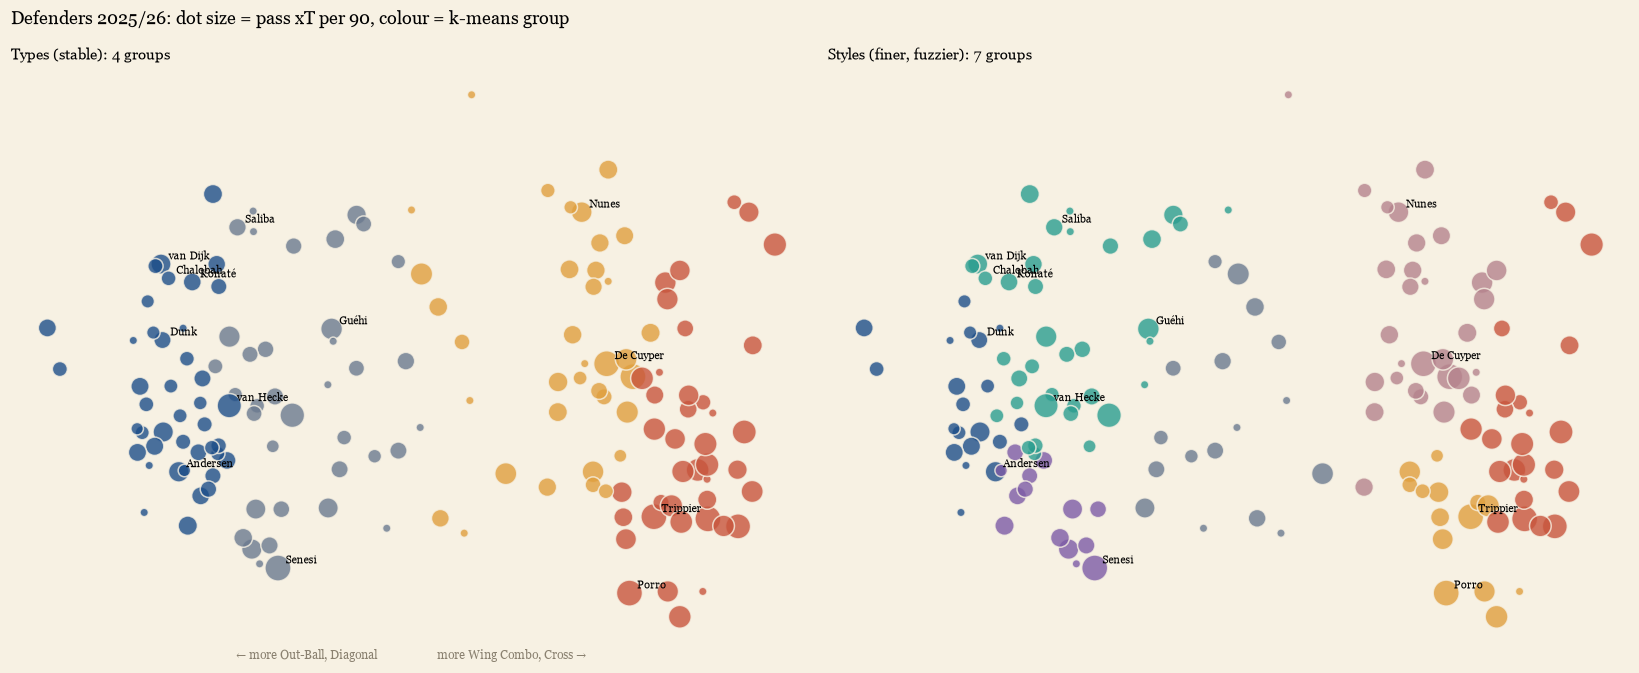

types : Overlapping full-backs (Wing Combo 30% · Recycle 18% · Cross 7%) | Hybrid full-backs (Wing Combo 21% · Recycle 18% · Link-up 7%) | Distributor centre-backs (Out-Ball 25% · Diagonal 25% · Push Wide 8%) | Direct centre-backs (Diagonal 17% · Out-Ball 16% · Push Wide 9%)
styles: Overlapping full-backs (Wing Combo 34% · Recycle 18% · Cross 7%) | Crossing full-backs (Down-the-Line 26% · Wing Combo 25% · Cross 6%) | Inverted full-backs (Recycle 18% · Push Wide 10% · Link-up 9%) | Wide centre-backs (Down-the-Line 24% · Recycle 16% · Long Ball 10%) | Ball-progressing centre-backs (Diagonal 21% · Push Wide 13% · Link-up 8%) | Diagonal centre-backs (Out-Ball 27% · Diagonal 27% · Push Wide 8%) | Direct centre-backs (Out-Ball 22% · Diagonal 20% · Long Ball 13%)


In [38]:
pl = payload['groups']['DEF']; P = pd.DataFrame(pl['players']); P = P[P.se == '2025-26']
fig, axs = plt.subplots(1, 2, figsize=(15, 6.2))
for ax, col, ty, ttl in ((axs[0], 'c', pl['types'], 'Types (stable): 4 groups'), (axs[1], 'c2', pl['styles'], 'Styles (finer, fuzzier): 7 groups')):
    colr = {t['id']: t['color'] for t in ty}; ax.scatter(P.x, P.y, s=30 + 260 * P.xt.fillna(0).clip(0, 12) / 12, c=P[col].map(colr), alpha=.8, edgecolors=BG)
    for _, r in P[P.k].iterrows(): ax.annotate(r.s, (r.x, r.y), xytext=(5, 3), textcoords='offset points', fontsize=7)
    ax.set_xticks([]); ax.set_yticks([]); [s.set_visible(False) for s in ax.spines.values()]; ax.set_title(ttl, loc='left', fontsize=10)
axs[0].set_xlabel(f"← {pl['axes']['x'][0]}                    {pl['axes']['x'][1]} →", color=MUTE, fontsize=8); plt.suptitle('Defenders 2025/26: dot size = pass xT per 90, colour = k-means group', x=.01, ha='left'); plt.tight_layout(); plt.show()
print('types :', ' | '.join(f"{t['name']} ({t['sig']})" for t in pl['types'])); print('styles:', ' | '.join(f"{t['name']} ({t['sig']})" for t in pl['styles']))

**Reading it.** The horizontal axis carries most of the differences (centre-backs on the left, full-backs on the right). Colouring by style shows the second layer inside each position. The interactive page lets you switch between types and styles, hover for the full pass mix of any player, switch position and season, and follow one player across seasons.

### What the groups say about change over time
Share of each type among each position's players, by season.

In [39]:
for gname in GROUPS:
    t = pd.DataFrame(payload['groups'][gname]['share'], index=[t['name'] for t in payload['groups'][gname]['types']]).T.loc[SEASONS[:-1]] * 100
    print(GROUPS[gname]); display(t.round(0).astype(int).T)

Defenders


,2013-14,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25,2025-26
Overlapping full-backs,40,38,43,37,39,42,42,38,37,30,28,26,26
Hybrid full-backs,11,12,8,15,12,8,12,12,15,20,23,23,23
Distributor centre-backs,34,33,36,32,27,29,33,35,32,31,26,26,27
Direct centre-backs,15,17,12,17,22,20,13,15,16,19,24,25,24


Midfielders


,2013-14,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25,2025-26
Attacking creators,20,24,20,18,31,26,25,29,23,30,28,29,28
Deep distributors,48,44,49,46,35,30,31,36,33,36,38,38,31
Balanced midfielders,32,32,30,36,34,43,43,36,43,33,34,33,41


Attackers (wide players and forwards)


,2013-14,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25,2025-26
Combination wingers,11,10,13,17,22,22,28,22,34,31,39,42,38
Link-up forwards,39,44,31,31,33,23,22,24,20,16,25,25,21
Crossing wide players,20,21,17,21,25,22,15,19,15,24,11,13,20
Inside creators,30,26,40,31,20,33,35,35,31,30,24,21,21


## 11. What changed in the league

Pass mix of each position group, 2013-17 against 2022-26, weighted by number of passes (percentage points of change).

,Goalkeepers,Centre-backs,Full-backs,Midfielders,Wide players and forwards
The Recycle,0.000,0.700,1.500,0.900,2.700
The Link-up,0.000,2.300,2.300,0.300,-5.600
The Wing Combo,0.000,0.800,-2.800,2.300,8.000
The Diagonal,5.600,0.900,1.000,-1.000,-0.400
The Cross,0.000,-0.100,-1.600,0.300,0.600
The Out-Ball,13.500,-2.200,0.700,-0.600,-0.200
The Push Wide,0.000,3.500,3.100,-1.200,-4.700
The Down-the-Line,-0.100,-2.900,-1.900,0.200,0.300
The Long Ball,-19.100,-2.900,-2.300,-1.200,-0.600


goalkeepers' share of their open-play passes (%):


,2013-17,2022-26
The Recycle,0.000,0.000
The Link-up,0.000,0.000
The Wing Combo,0.000,0.000
The Diagonal,21.000,26.000
The Cross,0.000,0.000
The Out-Ball,26.000,39.000
The Push Wide,0.000,0.000
The Down-the-Line,1.000,1.000
The Long Ball,53.000,33.000


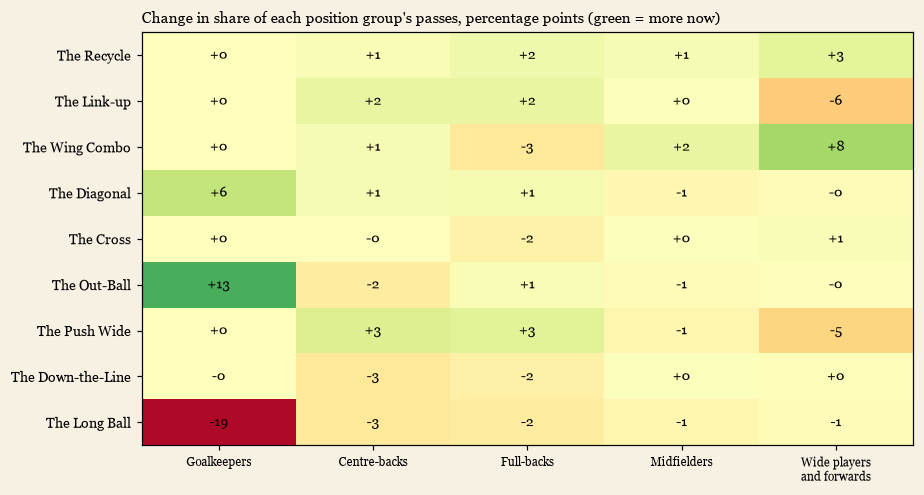

In [40]:
def grp_of(r):
    if r.role == 'GK': return 'Goalkeepers'
    if r.role == 'DEF': return 'Centre-backs' if r.fine == 'DC' else 'Full-backs'
    return 'Midfielders' if r.role == 'MID' else 'Wide players and forwards'
S['pg'] = S.apply(grp_of, axis=1); S['wn'] = S.n_passes
early_ = S[S.season <= '2016-17']; late_ = S[(S.season >= '2022-23') & (S.season <= '2025-26')]
wavg = lambda d: pd.Series({NAME[c]: (d[sc[c]] * d.wn).sum() / d.wn.sum() * 100 for c in range(9)})
change = pd.DataFrame({g_: wavg(late_[late_.pg == g_]) - wavg(early_[early_.pg == g_]) for g_ in ['Goalkeepers', 'Centre-backs', 'Full-backs', 'Midfielders', 'Wide players and forwards']})
display(change.round(1)); gk = pd.DataFrame({'2013-17': wavg(early_[early_.pg == 'Goalkeepers']), '2022-26': wavg(late_[late_.pg == 'Goalkeepers'])}); print("goalkeepers' share of their open-play passes (%):"); display(gk.round(0))
fig, ax = plt.subplots(figsize=(8.5, 4.6)); im = ax.imshow(change.to_numpy(), cmap='RdYlGn', vmin=-20, vmax=20, aspect='auto'); ax.set_xticks(range(5)); ax.set_xticklabels([c.replace(' and ', '\nand ') for c in change.columns], fontsize=8); ax.set_yticks(range(9)); ax.set_yticklabels(change.index, fontsize=9)
for i in range(9):
    for j_ in range(5): ax.text(j_, i, f'{change.iat[i, j_]:+.0f}', ha='center', va='center', fontsize=9)
ax.set_title('Change in share of each position group\'s passes, percentage points (green = more now)', fontsize=10, loc='left'); plt.tight_layout(); plt.show()

**Reading it.** The biggest change in a decade is the goalkeepers: the long forward ball fell from about 53% to about 33% of their open-play passes, replaced by short balls out to the flank and diagonals. Attackers moved toward the wing (wing combinations up, link-up passes down). Midfielders barely changed. Caveat: this is about *open play* only (goal kicks are excluded), and the attacker result is the least reliable because formations, and with them position labels, changed over the period.

## 12. Limitations

- **A continuum, not islands.** Silhouette is about 0.2 everywhere: the nine types and the player groups are useful slicings. Names are my reading of the numbers.
- **Choices made from a grid.** The number of clusters and the flag weight were chosen by stability; a temporal holdout (ARI about 0.83) suggests the structure carries across eras but not identically.
- **Tagging.** The provider's Chipped tag is the weakest input; its behaviour changed (including inside 2023/24), which forced the merge to nine types.
- **No defenders, pressure or ball height.** xP measures the difficulty of a *type* of pass, not of the moment, and is not a measure of skill. Pass xT ignores carrying, defending and off-ball work.
- **Position and team leak in.** A player's mix reflects his team's style and role as well as his habits; positions are the one a player most often started in, and formations changed over the period.
- **Small samples where it counts.** The current season is 8 matches per team old; xT before 2024/25 uses a grid fitted on the same data.

*Data: WhoScored event data. The raw files are not redistributed. Built with an AI coding assistant (Claude Code) under the author's direction; all decisions and checks reviewed by the author.*